# Лабораторная работа 1 — рабочий ноутбук

**ФИО:** Олихвер Виталий Николаевич

**Файлы данных:** `data/clients.csv`, `data/transactions.csv`

Исследуем снижение частоты операций клиентов банка с января 2024 по июнь 2025 года. Сначала проверим качество исходных данных и подготовим их к анализу, затем сравним активность и выделим группы для кампании. Изменения данных и их основания фиксируем в журнале.

## 0. Окружение и настройки


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

CLIENTS_PATH = f"data/{RAW_CLIENTS}"
TRANSACTIONS_PATH = f"data/{RAW_TXN}"


## 1. Загрузка сырых данных

Файлы получены из разных систем. Перед загрузкой посмотрим первые строки и определим кодировку, разделитель полей и запись десятичных чисел. Идентификаторы сначала прочитаем как строки, чтобы сохранить ведущие нули.


In [2]:
with open(CLIENTS_PATH, encoding='utf-8-sig') as file:
    for _ in range(2):
        print(repr(file.readline()))

with open(TRANSACTIONS_PATH, encoding='cp1251') as file:
    for _ in range(2):
        print(repr(file.readline()))


'client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in\n'
'C002139,1937-07-14,М,Санкт-Петербург,Массовый,Базовый,Дебетовая,22.04.2022,10.05.2022,Зарплата в нашем банке,22600.0,Нет,,,00352,Да\n'
'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990007;C002550;2023-11-27 13:45:54;4816,72;RUB;Кафе и рестораны;5812;Карта;успешно\n'


Первые строки читаются без искажений: клиенты разделены запятыми, операции — точками с запятой; у суммы десятичная запятая. В примере есть операция до начала задания; полный охват проверим в аудите.


In [3]:
clients_raw = pd.read_csv(CLIENTS_PATH, encoding='utf-8-sig', dtype='string', keep_default_na=False, na_values=[''])
transactions_raw = pd.read_csv(TRANSACTIONS_PATH, encoding='cp1251',
                               sep=';', decimal=',', dtype='string', keep_default_na=False, na_values=[''])

# Эти две таблицы дальше не меняем: они нужны для сравнения «до / после».
print('Клиенты:', clients_raw.shape)
print('Операции:', transactions_raw.shape)
clients_raw.info()
transactions_raw.info()


Клиенты: (5714, 16)
Операции: (627497, 9)
<class 'pandas.DataFrame'>
RangeIndex: 5714 entries, 0 to 5713
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   client_id           5714 non-null   string
 1   birth_date          5714 non-null   string
 2   gender              5714 non-null   string
 3   city                5714 non-null   string
 4   segment             5714 non-null   string
 5   loyalty_tier        5714 non-null   string
 6   card_type           5714 non-null   string
 7   registration_date   5714 non-null   string
 8   card_open_date      5714 non-null   string
 9   income_source       5714 non-null   string
 10  monthly_income      5175 non-null   string
 11  has_mobile_app      5714 non-null   string
 12  app_last_login      3524 non-null   string
 13  satisfaction_score  2336 non-null   string
 14  branch_code         5714 non-null   string
 15  marketing_opt_in    5714 non-null   strin

**Результат загрузки.** Загружены 5714 строк клиентов и 627497 строк операций. Все поля прочитаны строками; даты и числа проверим отдельно. Код отделения сохраняет ведущие нули.

## 2. Аудит качества

Проверим объём, ключи, пропуски, значения и связь файлов. Все количества аудита относятся к сырым строкам, включая повторы, если отдельно не указаны уникальные ID. Исходные таблицы не меняем.

### 2.1. Объём, типы, ключи, единица наблюдения

**Справочник клиентов.**


In [4]:
overview_clients = pd.DataFrame({
    'тип':clients_raw.dtypes.astype(str),
    'уникальных':clients_raw.nunique(),
    'пропусков':clients_raw.isna().sum(),
    'пропусков_%':(clients_raw.isna().mean()*100).round(2),
    'пример':clients_raw.iloc[0],
})
display(overview_clients)
print('Строк:',len(clients_raw),'; уникальных client_id:',clients_raw['client_id'].nunique())


,тип,уникальных,пропусков,пропусков_%,пример
client_id,string,5659,0,0.00,C002139
birth_date,string,4792,0,0.00,1937-07-14
gender,string,2,0,0.00,М
city,string,17,0,0.00,Санкт-Петербург
segment,string,4,0,0.00,Массовый
loyalty_tier,string,4,0,0.00,Базовый
card_type,string,3,0,0.00,Дебетовая
registration_date,string,3248,0,0.00,22.04.2022
card_open_date,string,2680,0,0.00,10.05.2022
income_source,string,3,0,0.00,Зарплата в нашем банке


Строк: 5714 ; уникальных client_id: 5659


В справочнике 5714 строк и 5659 уникальных ID. Строка пока не равна отдельному клиенту: повторные ID разберём перед анализом. Пропуски дохода, входа и оценки видны в сводке.

**Операции.**


In [5]:
overview_transactions = pd.DataFrame({
    'тип':transactions_raw.dtypes.astype(str),
    'уникальных':transactions_raw.nunique(),
    'пропусков':transactions_raw.isna().sum(),
    'пропусков_%':(transactions_raw.isna().mean()*100).round(2),
    'пример':transactions_raw.iloc[0],
})
display(overview_transactions)
print('Строк:',len(transactions_raw),'; уникальных txn_id:',transactions_raw['txn_id'].nunique())


,тип,уникальных,пропусков,пропусков_%,пример
txn_id,string,625997,0,0.0,990007
client_id,string,5994,0,0.0,C002550
txn_datetime,string,570322,0,0.0,2023-11-27 13:45:54
amount,string,327820,0,0.0,"4816,72"
currency,string,3,0,0.0,RUB
category,string,12,0,0.0,Кафе и рестораны
mcc_code,string,9,0,0.0,5812
channel,string,4,0,0.0,Карта
status,string,3,0,0.0,успешно


Строк: 627497 ; уникальных txn_id: 625997


В операциях 627497 строк и 625997 уникальных ID. Для частоты нужно разобрать повторы. Пустых полей нет. Встречаются 5994 ID клиентов, поэтому отдельно проверим пересечение со справочником.

### 2.2. Дубли


In [6]:
duplicate_audit = pd.DataFrame({
    'таблица': ['Клиенты', 'Операции'],
    'полных дублей': [clients_raw.duplicated().sum(), transactions_raw.duplicated().sum()],
    'лишних строк по ID': [clients_raw.duplicated('client_id').sum(),
                           transactions_raw.duplicated('txn_id').sum()],
})
display(duplicate_audit)


,таблица,полных дублей,лишних строк по ID
0,Клиенты,40,55
1,Операции,1283,1500


Полных повторов клиентов: 40, операций: 1283. Лишние строки по ID уже включают эти копии; столбцы не складываем. После временного удаления полных копий изучим разные версии ID.


In [7]:
client_distinct = clients_raw.drop_duplicates()
client_versions = client_distinct.loc[client_distinct.duplicated('client_id',keep=False)]
client_differences = client_versions.groupby('client_id').nunique(dropna=False)
print('Клиентских ID с разными версиями:',client_versions['client_id'].nunique())
display(client_differences.gt(1).sum())

client_versions.sort_values('client_id').head(4)


Клиентских ID с разными версиями: 15


birth_date             0
gender                 0
city                  11
segment               10
loyalty_tier           0
card_type              0
registration_date      0
card_open_date         0
income_source          0
monthly_income         0
has_mobile_app         0
app_last_login         0
satisfaction_score     0
branch_code            0
marketing_opt_in       0
dtype: int64

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
5371,C001435,1963-04-04,Ж,Нижний Новгород,Массовый,Серебро,Дебетовая,09.09.2014,12.05.2017,Зарплата в другом банке,-999.0,Да,2024-09,5,00534,Да
1323,C001435,1963-04-04,Ж,казань,Массовый,Серебро,Дебетовая,09.09.2014,12.05.2017,Зарплата в другом банке,-999.0,Да,2024-09,5,00534,Да
5095,C001483,1972-03-03,М,МОСКВА,Массовый,Базовый,Дебетовая,02.09.2020,18.06.2022,Не указан,<NA>,Да,2024-06,2,00326,Да
4419,C001483,1972-03-03,М,Нижний Новгород,Массовый,Базовый,Дебетовая,02.09.2020,18.06.2022,Не указан,<NA>,Да,2024-06,2,00326,Да


Разные версии анкет различаются только городом и сегментом; часть клиентов входит в обе проверки. Для города пока сравниваются сырые написания. Примеры показывают противоречия, но времени обновления анкеты нет, поэтому выбрать достоверную версию по ним нельзя.


In [8]:
txn_distinct = transactions_raw.drop_duplicates()
txn_versions = txn_distinct.loc[txn_distinct.duplicated('txn_id',keep=False)].copy()
txn_differences = txn_versions.groupby('txn_id').nunique(dropna=False)
print('ID операций с разными версиями:',txn_versions['txn_id'].nunique())
display(txn_differences.gt(1).sum())

txn_versions.sort_values('txn_id').head(6)


ID операций с разными версиями: 217


client_id         0
txn_datetime    217
amount            0
currency          0
category          0
mcc_code          0
channel           0
status            0
dtype: int64

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
7253,107236,C004773,2024-01-08,"1408,43",RUB,кафе и рестораны,5812,Карта,успешно
7254,107236,C004773,2024-01-08 16:03:11,"1408,43",RUB,кафе и рестораны,5812,Карта,успешно
8125,108105,C005088,2024-01-09,"2387,99",RUB,Продукты,5411,Карта,успешно
8126,108105,C005088,2024-01-09 19:15:15,"2387,99",RUB,Продукты,5411,Карта,успешно
17522,117478,C003599,2024-01-20,"852,32",RUB,АЗС,5541,Токен,успешно
17523,117478,C003599,2024-01-20 22:53:54,"852,32",RUB,АЗС,5541,Токен,успешно


У версий операции различается только `txn_datetime`. В примерах одна версия содержит дату, другая — дату со временем. Проверим совпадение календарного дня у всех повторных ID.


In [9]:
# Преобразуем текст в дату и время.
dates = pd.to_datetime(txn_versions['txn_datetime'],
                       format='ISO8601', errors='coerce')

# Оставляем только день, без времени суток.
txn_versions['calendar_date'] = dates.dt.date

# Проверяем, что непустые значения удалось прочитать.
parse_errors = txn_versions['txn_datetime'].notna() & dates.isna()
print('Ошибок чтения дат:', parse_errors.sum())

# Считаем, сколько разных дней встречается у каждого txn_id.
dates_per_id = txn_versions.groupby('txn_id')['calendar_date'].nunique(dropna=False)
different_dates = dates_per_id > 1
print('ID с разными датами:', different_dates.sum())


Ошибок чтения дат: 0
ID с разными датами: 0


Все даты повторных операций разобраны; ID с разной календарной датой нет. В сочетании с совпадением остальных полей это поддерживает решение сохранить при препроцессинге более точную запись времени. Сейчас сырые таблицы не изменены: проверка выполнена на отдельной таблице версий.

### 2.3. Соответствие данных описанию полей из задания

**Категориальные признаки клиентов.** Сверим значения с описанием задания. Частоты помогают обнаружить варианты написаний и явные обозначения неизвестного значения.


In [10]:
for column in ['gender', 'city', 'segment', 'loyalty_tier', 'card_type',
               'income_source', 'has_mobile_app', 'marketing_opt_in']:
    display(clients_raw[column].value_counts(dropna=False).to_frame('строк'))


,строк
gender,
М,2924
Ж,2790


,строк
city,
Москва,1103
Казань,746
Санкт-Петербург,610
Новосибирск,576
Нижний Новгород,564
Екатеринбург,478
казань,225
г. Москва,207
москва,180


,строк
segment,
Массовый,2857
Зарплатный,1639
Премиальный,983
Private,235


,строк
loyalty_tier,
Базовый,2884
Серебро,1518
Золото,1014
Платина,298


,строк
card_type,
Дебетовая,3958
Кредитная,1242
Премиальная,514


,строк
income_source,
Зарплата в нашем банке,2621
Не указан,1581
Зарплата в другом банке,1512


,строк
has_mobile_app,
Да,3524
Нет,2190


,строк
marketing_opt_in,
Да,5033
Нет,681


У городов есть эквивалентные написания: регистр, префикс «г.», пробелы и сокращения. Их нормализуем перед разбором версий анкет.

«Не указан» в источнике зарплаты означает отсутствие сведений; это не отдельный вид зарплаты и не основание относить клиента к другому банку.

В 681 строках согласие равно «Нет». В кампанию включаем только клиентов с явным согласием «Да».

**Категориальные признаки операций.** Проверим валюты, категории, каналы и статусы.


In [11]:
for column in ['currency', 'category', 'channel', 'status']:
    display(transactions_raw[column].value_counts(dropna=False).to_frame('строк'))


,строк
currency,
RUB,624977
EUR,1277
USD,1243


,строк
category,
Продукты,164717
Одежда и обувь,70763
Транспорт,65942
АЗС,58276
Кафе и рестораны,48961
Развлечения и досуг,48238
Аптеки,45086
Онлайн-сервисы,43868
Связь и интернет,29282


,строк
channel,
Карта,320113
СБП,113305
Токен,105450
Онлайн-банк,88629


,строк
status,
успешно,607595
отклонено,12314
возврат,7588


RUB, EUR и USD задают разные единицы суммы: без курсов суммы не складываем, число операций сравнивать можно. У категорий есть смысловые дубли кафе и связи.

Успешные операции, отказы и возвраты разделим при выборе метрики. Для проверки смысла отрицательных сумм сопоставим их знак со статусом.

**Преобразование чисел и диапазоны.**


In [12]:
income_audit = pd.to_numeric(clients_raw['monthly_income'], errors='coerce')
score_audit = pd.to_numeric(clients_raw['satisfaction_score'], errors='coerce')
amount_audit = pd.to_numeric(transactions_raw['amount'].str.replace(',', '.', regex=False),
                             errors='coerce')
numeric_checks = []
for name, raw, parsed in [
    ('monthly_income', clients_raw['monthly_income'], income_audit),
    ('satisfaction_score', clients_raw['satisfaction_score'], score_audit),
    ('amount', transactions_raw['amount'], amount_audit),
]:
    numeric_checks.append({
        'поле': name,
        'сырых строк': len(raw),
        'пропусков': raw.isna().sum(),
        'ошибок разбора': (raw.notna() & parsed.isna()).sum(),
        'min': parsed.min(), 'max': parsed.max(),
    })
pd.DataFrame(numeric_checks)


,поле,сырых строк,пропусков,ошибок разбора,min,max
0,monthly_income,5714,539,0,-999.00,880200.00
1,satisfaction_score,5714,3378,0,1.00,5.00
2,amount,627497,0,0,-45015.04,89419.22


Непустые значения трёх числовых полей преобразуются без ошибок. Однако в доходе и суммах есть отрицательные значения. Успешное преобразование строки в число не подтверждает экономическую корректность — эти значения нужно проверить отдельно.


In [13]:
display(income_audit.describe())

income_audit.loc[income_audit.lt(0)].value_counts()


count          5175.0
mean     95434.185952
std      81187.296567
min            -999.0
25%           52700.0
50%           73700.0
75%          109700.0
max          880200.0
Name: monthly_income, dtype: Float64

monthly_income
-999.0    52
Name: count, dtype: Int64

Среднее дохода выше медианы, а единственное отрицательное значение равно −999. Это похоже на техническое обозначение неизвестного дохода. При обработке сохраним отдельный флаг; клиента целиком удалять не требуется.


In [14]:
amount_by_currency = transactions_raw[['currency']].assign(amount=amount_audit)
display(amount_by_currency.groupby('currency')['amount'].agg(['count', 'min', 'median', 'max']))

pd.crosstab(transactions_raw['status'],amount_audit.lt(0),colnames=['сумма отрицательная'])


,count,min,median,max
currency,,,,
EUR,1277,-163.08,11.91,574.78
RUB,624977,-45015.04,1082.05,89419.22
USD,1243,-105.95,10.69,762.59


сумма отрицательная,False,True
status,,
возврат,0,7588
отклонено,12314,0
успешно,607595,0


Отрицательные суммы относятся только к возвратам. Такой знак соответствует смыслу операции, поэтому сохраняем суммы. Роль возвратов в частоте определим при выборе метрики.


In [15]:
print('Оценок вне целых 1–5:',(score_audit.notna() & ~score_audit.isin([1,2,3,4,5])).sum())


Оценок вне целых 1–5: 0


Все непустые оценки — целые значения 1–5. Оценка порядковая: описываем частоты, медиану и моду. Заполненность и представительность ответивших проверим в разделе 3.3.

**Форматы дат и временной охват.**


In [16]:
SNAPSHOT = pd.Timestamp('2025-06-30')
START = pd.Timestamp('2024-01-01')
SPLIT = pd.Timestamp('2025-01-01')
END = pd.Timestamp('2025-07-01')
date_formats = {'birth_date': '%Y-%m-%d', 'registration_date': '%d.%m.%Y',
                'card_open_date': '%d.%m.%Y', 'app_last_login': '%Y-%m'}

client_dates = pd.DataFrame(index=clients_raw.index)
date_checks = []
for column, fmt in date_formats.items():
    client_dates[column] = pd.to_datetime(clients_raw[column], format=fmt, errors='coerce')
    date_checks.append({
        'поле': column, 'пропусков': clients_raw[column].isna().sum(),
        'ошибок преобразования': (clients_raw[column].notna() & client_dates[column].isna()).sum(),
        'min': client_dates[column].min(), 'max': client_dates[column].max(),
    })
txn_dates = pd.to_datetime(transactions_raw['txn_datetime'], format='ISO8601', errors='coerce')
date_checks.append({'поле': 'txn_datetime', 'пропусков': transactions_raw['txn_datetime'].isna().sum(),
                    'ошибок преобразования': (transactions_raw['txn_datetime'].notna() & txn_dates.isna()).sum(),
                    'min': txn_dates.min(), 'max': txn_dates.max()})
display(pd.DataFrame(date_checks))


,поле,пропусков,ошибок преобразования,min,max
0,birth_date,0,0,1936-07-26 00:00:00,2002-02-13 00:00:00
1,registration_date,0,0,2010-03-03 00:00:00,2025-03-26 00:00:00
2,card_open_date,0,0,2016-01-01 00:00:00,2025-05-16 00:00:00
3,app_last_login,2190,0,2024-01-01 00:00:00,2025-06-01 00:00:00
4,txn_datetime,0,0,2023-11-27 13:45:54,2026-08-01 20:59:07


Ошибок разбора непустых дат нет. Операции охватывают 27.11.2023–01.08.2026, шире задания. Посчитаем нарушения периода и хронологии.


In [17]:
checks = pd.Series({
    'рождение после среза': client_dates['birth_date'].gt(SNAPSHOT).sum(),
    'регистрация после среза': client_dates['registration_date'].gt(SNAPSHOT).sum(),
    'карта открыта после среза': client_dates['card_open_date'].gt(SNAPSHOT).sum(),
    'регистрация раньше рождения': client_dates['registration_date'].lt(client_dates['birth_date']).sum(),
    'карта раньше регистрации': client_dates['card_open_date'].lt(client_dates['registration_date']).sum(),
    'вход раньше месяца регистрации': (client_dates['app_last_login'].dt.to_period('M') <
                                       client_dates['registration_date'].dt.to_period('M')).sum(),
    'вход после среза': client_dates['app_last_login'].ge(END).sum(),
    'операция до периода': txn_dates.lt(START).sum(),
    'операция после периода': txn_dates.ge(END).sum(),
})
display(checks)


рождение после среза               0
регистрация после среза            0
карта открыта после среза          0
регистрация раньше рождения        0
карта раньше регистрации           0
вход раньше месяца регистрации    25
вход после среза                   0
операция до периода                2
операция после периода            80
dtype: int64

Входов раньше месяца регистрации: 25; операций до периода: 2, после периода: 80. Остальные проверки нарушений не выявили. Вход сравниваем по месяцу. Дата открытия относится к текущей карте, поэтому более ранняя операция сама по себе не доказывала бы ошибку.


In [18]:
display(pd.crosstab(clients_raw['has_mobile_app'], client_dates['app_last_login'].isna(),
                    colnames=['последний вход пропущен']))


последний вход пропущен,False,True
has_mobile_app,,
Да,3524,0
Нет,0,2190


У 2190 строк без приложения нет месяца входа; у 3524 строк с приложением он указан. Это поддерживает структурное объяснение исходной пустоты. Противоречивые месяцы проверены отдельно.


In [19]:
pd.crosstab(transactions_raw['category'], transactions_raw['mcc_code'])


mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,18,19,18,58128,18,22,20,17,16
Аптеки,15,11,13,21,16,7,13,44969,21
Кафе и рестораны,31,15,15,18,14,48821,17,12,18
Кафе/рестораны,4,3,8,10,4,16321,5,7,4
Одежда и обувь,17,25,18,23,70599,19,19,26,17
Онлайн-сервисы,21,7,12,11,17,20,43753,15,12
Продукты,44,67,164282,48,60,65,57,48,46
Развлечения и досуг,14,6,19,12,17,13,18,13,48126
Связь и Интернет,12,19487,5,3,7,10,4,5,5


### 2.4. Связь между таблицами

В разделе 2.1 число уникальных client_id в операциях оказалось больше, чем в справочнике. Проверим, каким операциям можно сопоставить анкету клиента. Затем выполним обратную проверку и сопоставим даты операций с датами регистрации и открытия текущей карты.

**Операции клиентов вне справочника.**


In [20]:
unknown_client = ~transactions_raw['client_id'].isin(clients_raw['client_id'])

print('Сырых строк операций вне справочника:', unknown_client.sum(),
      'из', len(transactions_raw))
print('Уникальных client_id вне справочника:',
      transactions_raw.loc[unknown_client, 'client_id'].nunique())

no_transactions = ~clients_raw['client_id'].isin(transactions_raw['client_id'])

print('Уникальных клиентов справочника без операций:',
      clients_raw.loc[no_transactions, 'client_id'].nunique(),
      'из', clients_raw['client_id'].nunique())

outside_registry_n = transactions_raw.loc[unknown_client, 'client_id'].nunique()


Сырых строк операций вне справочника: 29207 из 627497
Уникальных client_id вне справочника: 341
Уникальных клиентов справочника без операций: 6 из 5659


Операциям вне справочника нельзя сопоставить анкету и согласие из выданных данных. Разный охват источников сам по себе не доказывает ошибку ID. В обратном направлении есть клиенты без строк операций: сохраним их в базе с нулевой наблюдаемой частотой.

**Операции раньше регистрации.** Даты регистрации у повторных анкет совпадают. Берём одну дату на `client_id` и подставляем её к операциям через `map`. Проверку можно выполнить только там, где дата регистрации известна.


In [21]:
registration_dates = client_dates['registration_date'].groupby(clients_raw['client_id']).first()
txn_registration = transactions_raw['client_id'].map(registration_dates)
before_registration = txn_dates < txn_registration

print('Сырых строк операций с известной датой регистрации:',
      txn_registration.notna().sum(), 'из', len(transactions_raw))
print('Операций раньше регистрации:', before_registration.sum())

# Проверяем фактическое начало истории относительно текущей карты.
card_open_dates = client_dates['card_open_date'].groupby(clients_raw['client_id']).first()
period_rows = txn_dates.ge(START) & txn_dates.lt(END) & ~unknown_client
first_operation = pd.DataFrame({
    'client_id': transactions_raw.loc[period_rows, 'client_id'],
    'first_operation': txn_dates.loc[period_rows],
}).groupby('client_id')['first_operation'].min()
card_history_audit = pd.DataFrame({'registration_date': registration_dates,
                                  'card_open_date': card_open_dates,
                                  'first_operation': first_operation})
print('Клиентов с операциями в периоде и известной датой карты:',
      card_history_audit.dropna(subset=['first_operation', 'card_open_date']).shape[0])
print('Первая операция раньше открытия текущей карты:',
      (card_history_audit['first_operation'] < card_history_audit['card_open_date']).sum())
print('Ранняя регистрация, текущая карта открыта после начала базы:',
      (card_history_audit['registration_date'].le(START)
       & card_history_audit['card_open_date'].gt(START)).sum())


Сырых строк операций с известной датой регистрации: 598290 из 627497
Операций раньше регистрации: 0


Клиентов с операциями в периоде и известной датой карты: 5653
Первая операция раньше открытия текущей карты: 1
Ранняя регистрация, текущая карта открыта после начала базы: 673


Регистрация известна для 598290 из 627497 сырых операций; раньше регистрации операций нет.

**Начало наблюдаемой истории.** В периоде задания операции есть у 5653 клиентов справочника; только у одного первая операция предшествует открытию текущей карты. Это согласуется с тем, что история в файле в основном начинается с текущей карты. Ранняя регистрация в банке не обеспечивает полный 2024 год: у 673 таких клиентов карта открыта позже начала базы.

Для сравнения полных окон потребуем и регистрацию, и открытие текущей карты не позже 01.01.2024. Иначе ранние месяцы могут быть ненаблюдаемыми, и подстановка нулей создаст искусственный рост. Поздние карты сохраняем в очищенных данных, но исключаем из сравнения и кампании. Полнота внутри допустимого окна остаётся ограничением выгрузки.

**Выводы по аудиту.** Требуются удаление полных копий, разбор разных версий ID, нормализация написаний и обработка −999. Проверены знак возвратов, валюты, даты, охват справочника и доступность базового периода. Пропуски и необычные положительные значения исследуем отдельно.

## 3. Препроцессинг

Изменения рабочих копий и их основания фиксируем в журнале; исходные таблицы сохраняем для сравнения.


In [22]:
log_rows = []

def add_log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    log_rows.append({
        'field': field,
        'issue': issue,
        'scope': scope,
        'n_rows': int(n_rows),
        'value_before': value_before,
        'action': action,
        'value_after': value_after,
        'rationale': rationale,
    })

funnel_rows = [{'этап': 'Сырые операции', 'строк': len(transactions_raw)}]


### 3.1. Типы, даты, числа

**Полные дубли.**

Аудит выявил строки, совпадающие по всем полям. Оставляем по одной копии: иначе один клиент или одна операция будут посчитаны несколько раз. Различающиеся версии пока сохраняем.


In [23]:
clients = clients_raw.copy()
transactions = transactions_raw.copy()

n = clients.duplicated().sum()
clients = clients.drop_duplicates()
add_log('clients', 'Полные дубли', 'Повторные строки по всем полям clients_raw', n,
        'Несколько одинаковых строк', 'удалено', 'Одна копия строки',
        'Не учитывать одну анкету несколько раз')
print('Удалено полных дублей клиентов:', n)

n = transactions.duplicated().sum()
transactions = transactions.drop_duplicates()
add_log('transactions', 'Полные дубли', 'Повторные строки по всем полям transactions_raw', n,
        'Несколько одинаковых строк', 'удалено', 'Одна копия строки',
        'Не учитывать одну операцию несколько раз')
print('Удалено полных дублей операций:', n)
funnel_rows.append({'этап': 'После полных дублей', 'строк': len(transactions)})


Удалено полных дублей клиентов: 40


Удалено полных дублей операций: 1283


Удалены 40 полных дублей клиентов и 1283 полных дубля операций. Осталось 5674 строки анкет и 626214 строк операций. Повторные ID с различающимися значениями ещё не разрешены.

**Версии операции с разной точностью времени.**

В разделе 2.2 у повторных txn_id проверено совпадение календарного дня и остальных полей. Дополнительно проверим, что у каждого такого ID есть ровно одна запись даты без времени и одна запись со временем. Это исключит произвольный выбор между двумя разными точными временами одного дня.


In [24]:
transactions['time_missing'] = transactions['txn_datetime'].str.len() == 10
add_log('time_missing', 'В части записей источник содержит только дату',
        'Все операции после удаления полных дублей', len(transactions),
        'Отдельного признака точности нет', 'добавлено', 'True, если исходное время отсутствует',
        'Отличать техническое 00:00 после преобразования от указанного в источнике времени')

repeated_id = transactions['txn_id'].duplicated(keep=False)
pair_check = transactions.loc[repeated_id].groupby('txn_id')['time_missing'].agg(
    n='size', without_time='sum')

print('Повторных ID:', len(pair_check))
print('У каждого две версии, одна без времени:',
      ((pair_check['n'] == 2) & (pair_check['without_time'] == 1)).all())


Повторных ID: 217
У каждого две версии, одна без времени: True


Проверка подтвердила: у всех 217 повторных ID ровно две версии — одна со временем, другая только с датой. Вместе с уже проверенным совпадением дня и остальных полей это позволяет удалить только менее точную строку. time_missing сохраняем в данных: True означает, что источник не указал время.


In [25]:
remove = repeated_id & transactions['time_missing']
n = remove.sum()
transactions = transactions.loc[~remove]

add_log('txn_id, txn_datetime', 'Разная точность записи одной операции',
        'Повторные txn_id: совпали календарный день и остальные поля', n,
        'Дата и дата со временем', 'удалено', 'Удалена только версия без времени',
        'Одна операция учитывается один раз; более точная запись сохраняется')
funnel_rows.append({'этап': 'Один txn_id — одна операция', 'строк': len(transactions)})
print('Удалено менее точных версий:', n)
print('Уникальных операций:', len(transactions))
print('Операций без исходного времени:', transactions['time_missing'].sum())


Удалено менее точных версий: 217
Уникальных операций: 625997
Операций без исходного времени: 50002


Осталось 625997 уникальных операций. У 50002 из них источник содержит только дату. После преобразования появится время 00:00, но это не доказательство операции в полночь. Флаг time_missing=True сохраняется после преобразования и попадёт в clean. Месяц известен, поэтому помесячный анализ допустим; точное время суток для этих операций восстановить нельзя.

**Преобразование дат.**

Форматы и отсутствие ошибок разбора проверены в аудите. Применяем те же форматы к рабочим копиям. Месяц последнего входа сохраняем с его исходной точностью: при сравнении с регистрацией будем сопоставлять месяцы.


In [26]:
for column, fmt in date_formats.items():
    clients[column] = pd.to_datetime(clients[column], format=fmt, errors='coerce')

transactions['txn_datetime'] = pd.to_datetime(transactions['txn_datetime'],
                                            format='ISO8601', errors='coerce')
print('Тип даты операции:', transactions['txn_datetime'].dtype)


Тип даты операции: datetime64[us]


**Преобразование чисел.**

В аудите непустые значения преобразовались без ошибок. Доход и оценку делаем числовыми; в сумме сначала заменяем десятичную запятую. Идентификаторы, MCC и код отделения остаются строками, чтобы сохранить их смысл и ведущие нули. Необычные числовые значения обрабатываем отдельно от преобразования типа.


In [27]:
for column in ['monthly_income', 'satisfaction_score']:
    clients[column] = pd.to_numeric(clients[column], errors='coerce')

transactions['amount'] = transactions['amount'].str.replace(',', '.', regex=False)
transactions['amount'] = pd.to_numeric(transactions['amount'], errors='coerce')

add_log('birth_date, registration_date, card_open_date, app_last_login, monthly_income, satisfaction_score',
        'Приведение клиентских полей к нужным типам', 'Все строки clients после удаления полных дублей', len(clients),
        f'Строки; форматы дат {date_formats}; доход и оценка — числовые строки',
        'преобразовано', 'Даты — datetime; доход и оценка — числа',
        'Для сравнения дат, расчёта возраста и числовых распределений; ошибки разбора проверены в аудите')
add_log('txn_datetime, amount', 'Приведение полей операций к нужным типам',
        'Все уникальные операции после разрешения версий', len(transactions),
        'ISO-дата строкой; сумма строкой с десятичной запятой', 'преобразовано',
        'Дата — datetime; сумма — число в исходной валюте',
        'Для выделения месяца и числовых проверок; неизвестное время отмечено отдельным флагом')
clients[['monthly_income', 'satisfaction_score']].dtypes


monthly_income        Float64
satisfaction_score      Int64
dtype: object

### 3.2. Категориальные признаки

**Варианты названий городов.**

В списке значений обнаружены различия регистра, пробелы и сокращения одних и тех же городов. Объединяем только эти проверенные варианты. Содержательные противоречия между анкетами одного клиента проверим после нормализации.


In [28]:
city_map = {
    'москва': 'Москва', 'г. москва': 'Москва',
    'санкт-петербург': 'Санкт-Петербург', 'санкт петербург': 'Санкт-Петербург',
    'г. санкт-петербург': 'Санкт-Петербург', 'спб': 'Санкт-Петербург',
    'казань': 'Казань',
    'новосибирск': 'Новосибирск', 'г. новосибирск': 'Новосибирск',
    'екатеринбург': 'Екатеринбург', 'г.екатеринбург': 'Екатеринбург',
    'нижний новгород': 'Нижний Новгород', 'н. новгород': 'Нижний Новгород',
}
city_new = clients['city'].str.strip().str.lower().map(city_map)
n = (clients['city'] != city_new).sum()
clients['city'] = city_new
add_log('city', 'Разные написания одного города', 'Известные варианты из city_map', n,
        '17 написаний', 'нормализация', '6 городов',
        'Объединены эквивалентные названия из исходного списка значений')
print('Изменено строк анкет:', n)
display(clients['city'].value_counts())


Изменено строк анкет: 1629


city
Москва             1649
Казань              966
Санкт-Петербург     922
Новосибирск         721
Нижний Новгород     715
Екатеринбург        701
Name: count, dtype: int64

Изменены 1629 строк анкет; 17 исходных написаний сведены к шести городам. Это ещё не частоты уникальных клиентов: повторные версии анкет пока присутствуют.

**Варианты названий категорий.**

По списку значений кафе представлены тремя подписями, связь — двумя. Объединяем эти смысловые дубли; остальные названия сохраняем.


In [29]:
category_map = {
    'кафе и рестораны': 'Кафе и рестораны',
    'Кафе/рестораны': 'Кафе и рестораны',
    'Связь и Интернет': 'Связь и интернет',
}
n = transactions['category'].isin(category_map).sum()
transactions['category'] = transactions['category'].replace(category_map)
add_log('category', 'Разные подписи одной категории', 'Значения из category_map', n,
        '12 подписей', 'нормализация', '9 категорий', 'Объединены только эквивалентные названия')
print('Изменено строк операций:', n)
display(transactions['category'].value_counts())


Изменено строк операций: 52234


category
Продукты               164324
Кафе и рестораны        81577
Одежда и обувь          70597
Транспорт               65789
АЗС                     58146
Связь и интернет        48704
Развлечения и досуг     48118
Аптеки                  44989
Онлайн-сервисы          43753
Name: count, dtype: Int64

Исправлены подписи в 52234 уникальных операциях. Теперь девять категорий соответствуют смысловому списку из задания.

**Оставшиеся противоречия в анкетах.**

Проверим повторные анкеты ещё раз: различие строковых написаний уже устранено. Если у одного ID остаются разные город или сегмент, без даты обновления анкеты нельзя выбрать достоверное значение.


In [30]:
client_conflicts = clients.groupby('client_id')[['city', 'segment']].nunique(dropna=False) > 1
display(client_conflicts.sum())


city       11
segment    10
dtype: int64

После нормализации конфликт города остаётся у 11 ID, сегмента — у 10. Сохраняем согласованные сведения, а неизвестными делаем только спорные поля.


In [31]:
conflict_ids = client_conflicts.index[client_conflicts.any(axis=1)]
conflict_rows = clients['client_id'].isin(conflict_ids).sum()

for column in ['city', 'segment']:
    ids = client_conflicts.index[client_conflicts[column]]
    mask = clients['client_id'].isin(ids)
    clients.loc[mask, column] = pd.NA

# Проверяем, что после замены спорных полей остальные сведения совпадают.
assert (clients.groupby('client_id').nunique(dropna=False) <= 1).all().all()
n = clients.duplicated('client_id').sum()
clients = clients.drop_duplicates('client_id')
add_log('client_id, city, segment', 'Разрешение противоречащих версий анкеты',
        f'Все {conflict_rows} строк версий для {len(conflict_ids)} client_id после нормализации', conflict_rows,
        'Разные город или сегмент у одного ID', 'исправлено',
        f'Спорные поля — NA; удалено {n} лишних версий; одна анкета на ID',
        'Нет времени обновления: сохраняем согласованные сведения, затем объединяем совпавшие версии')
print('Уникальных клиентов:', len(clients))


Уникальных клиентов: 5659


Удалено 15 лишних версий, осталось 5659 клиентов. Неизвестный город у 11, сегмент у 10 клиентов.

**Соответствие категории и MCC.** Покажем доли сочетаний внутри категории: это позволяет сравнить частые и редкие категории.


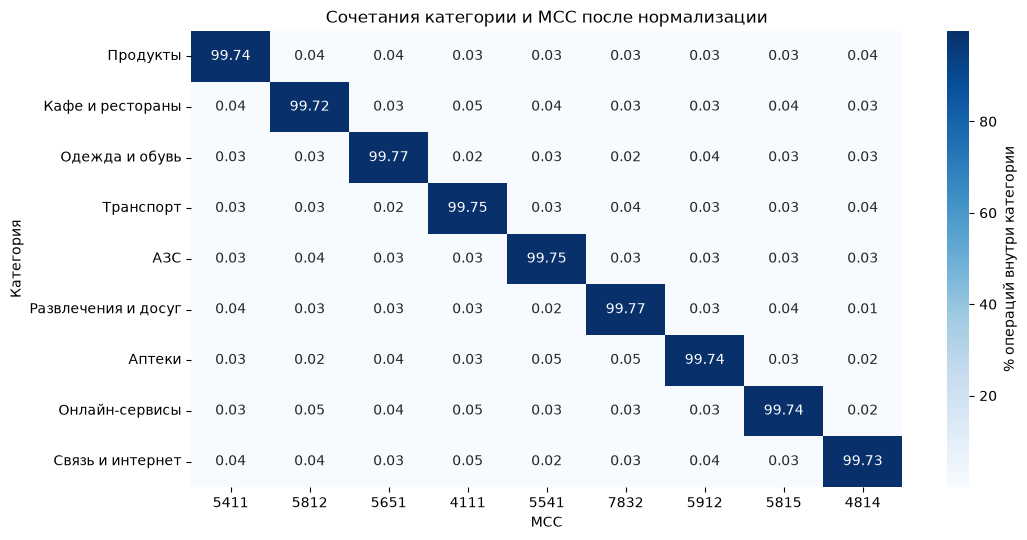

In [32]:
mcc_map = {
    '5411': 'Продукты', '5812': 'Кафе и рестораны', '5651': 'Одежда и обувь',
    '4111': 'Транспорт', '5541': 'АЗС', '7832': 'Развлечения и досуг',
    '5912': 'Аптеки', '5815': 'Онлайн-сервисы', '4814': 'Связь и интернет',
}
category_mcc = pd.crosstab(transactions['category'], transactions['mcc_code'], normalize='index') * 100
category_mcc = category_mcc.reindex(index=list(mcc_map.values()), columns=list(mcc_map))

plt.figure(figsize=(11, 5.5))
sns.heatmap(category_mcc, annot=True, fmt='.2f', cmap='Blues',
            cbar_kws={'label': '% операций внутри категории'})
plt.title('Сочетания категории и MCC после нормализации')
plt.xlabel('MCC')
plt.ylabel('Категория')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Основная доля операций приходится на ожидаемые сочетания, но вне диагонали видны небольшие ненулевые доли. Посчитаем расхождения. Преобладание пары не доказывает, что текст категории или MCC всегда указан верно.


In [33]:
transactions['category_mcc_conflict'] = transactions['category'] != transactions['mcc_code'].map(mcc_map)
n = transactions['category_mcc_conflict'].sum()
print('Расхождений категории и MCC:', n, 'из', len(transactions))
print('Доля расхождений, %:', round(100 * n / len(transactions), 3))

add_log('category_mcc_conflict', 'Контроль расхождений категории и MCC',
        f'Все уникальные операции; расхождение у {n} из них', len(transactions),
        'Флага расхождения нет', 'добавлено', 'Добавлен флаг; исходные category и MCC сохранены',
        'Для основного анализа выбираем category; без эталона нельзя исправить каждую спорную метку')


Расхождений категории и MCC: 1615 из 625997
Доля расхождений, %: 0.258


**Решение.** Найдено 1615 расхождений из 625997 операций (0.258%). Для основного анализа выбираем текстовую `category`, MCC и флаг расхождения сохраняем. Эталона нет. Сравним общие доли при двух классификациях на одном составе операций.


In [34]:
category_share = pd.DataFrame({
    'по категории, %': transactions['category'].value_counts() / len(transactions) * 100,
    'по MCC, %': transactions['mcc_code'].map(mcc_map).value_counts() / len(transactions) * 100,
})
category_share['разница, п.п.'] = category_share['по MCC, %'] - category_share['по категории, %']
category_share.round(3)


,"по категории, %","по MCC, %","разница, п.п."
Продукты,26.25,26.204,-0.046
Кафе и рестораны,13.032,13.025,-0.006
Одежда и обувь,11.278,11.280,0.003
Транспорт,10.509,10.514,0.004
АЗС,9.289,9.293,0.005
Связь и интернет,7.78,7.788,0.008
Развлечения и досуг,7.687,7.697,0.011
Аптеки,7.187,7.197,0.01
Онлайн-сервисы,6.989,7.001,0.012


Общие доли категорий мало меняются. Состав кампании по MCC проверим отдельно после построения групп: устойчивость общих долей не гарантирует совпадения индивидуального отбора.

### 3.3. Пропуски

Посчитаем пропуски среди уникальных клиентов, проверим связь заполненности с источником зарплаты и уровнем лояльности, затем выберем способ обработки. Исходную пустоту дохода отличаем от −999.


In [35]:
clients['income_missing_raw'] = clients['monthly_income'].isna()
clients['score_missing'] = clients['satisfaction_score'].isna()

missing = clients.isna().sum()
missing_summary = pd.DataFrame({
    'пропусков': missing,
    'доля клиентов, %': missing / len(clients) * 100,
})
missing_summary.loc[missing > 0].round(2)


,пропусков,"доля клиентов, %"
city,11,0.19
segment,10,0.18
monthly_income,534,9.44
app_last_login,2171,38.36
satisfaction_score,3350,59.20


Оценка отсутствует у большинства клиентов, доход — реже. Пустота входа связана с отсутствием приложения, города и сегмента — с обработанными противоречиями. В следующих таблицах `n` — размер группы, `missing` — число исходных пропусков, `share` — их процент.


In [36]:
income_missing_by_source = clients.groupby('income_source')['income_missing_raw'].agg(
    n='size', missing='sum', share='mean')
income_missing_by_source['share'] *= 100
income_missing_by_source.round(2)


,n,missing,share
income_source,,,
Зарплата в другом банке,1499,37,2.47
Зарплата в нашем банке,2596,105,4.04
Не указан,1564,392,25.06


При неуказанном источнике зарплаты доход отсутствует заметно чаще. Заполненность связана с наблюдаемым признаком, поэтому предположение MCAR сомнительно. По одной такой таблице нельзя различить MAR и MNAR: вероятность пропуска может зависеть и от неизвестного дохода.


In [37]:
score_missing_by_tier = clients.groupby('loyalty_tier')['score_missing'].agg(
    n='size', missing='sum', share='mean')
score_missing_by_tier['share'] *= 100
score_missing_by_tier.round(2)


,n,missing,share
loyalty_tier,,,
Базовый,2862,1916,66.95
Золото,1003,311,31.01
Платина,296,89,30.07
Серебро,1498,1034,69.03


Доля пропущенных оценок различается между уровнями лояльности, поэтому оценки ответивших могут не отражать всю базу. Как и для дохода, связь с наблюдаемыми признаками не позволяет различить MAR и MNAR. Пропуски оценок не заменяем ни низким, ни средним баллом.

**Отрицательное значение дохода −999.** Считаем его обозначением неизвестного дохода: заменяем пропуском и сохраняем отдельный флаг.


In [38]:
clients['income_invalid'] = (clients['monthly_income'] == -999).fillna(False)
n = clients['income_invalid'].sum()
clients.loc[clients['income_invalid'], 'monthly_income'] = np.nan
add_log('monthly_income', 'Повторяющееся отрицательное значение дохода −999', 'monthly_income=-999', n,
        '-999 руб./месяц', 'заменено', 'Пропуск; исходный случай отмечен income_invalid',
        'Рассматриваем −999 как обозначение неизвестного дохода; сохраняем отдельный флаг')
print('Заменено значений −999 у уникальных клиентов:', n)


Заменено значений −999 у уникальных клиентов: 50


Заменены 50 значений у уникальных клиентов; в исходном файле было 52 строки с −999 из-за повторов. Неизвестных доходов стало 584. Отсутствие дохода не мешает считать операции, поэтому клиентов сохраняем.

**Противоречивые месяцы последнего входа.**

В разделе 2.3 найден вход раньше месяца регистрации. Сравниваем именно месяцы: `app_last_login` не содержит день и после преобразования получает первое число месяца. Вход в месяце регистрации сам по себе не является нарушением.

Для дальнейшего анализа считаем дату регистрации опорной, а противоречащий ей месяц входа заменяем пропуском. Сохраняем флаг этой обработки.


In [39]:
login_month = clients['app_last_login'].dt.to_period('M')
registration_month = clients['registration_date'].dt.to_period('M')
clients['login_invalid'] = (login_month < registration_month).fillna(False)
n = clients['login_invalid'].sum()
clients.loc[clients['login_invalid'], 'app_last_login'] = pd.NaT
add_log('app_last_login', 'Месяц входа противоречит дате регистрации',
        'Месяц входа < месяца регистрации', n,
        'Месяц входа раньше месяца регистрации', 'заменено', 'NaT; случай отмечен login_invalid',
        'Не использовать противоречивый месяц при анализе давности входа')
print('Заменено противоречивых месяцев входа:', n)


Заменено противоречивых месяцев входа: 25


Исключено 25 противоречивых месяцев. Поле пусто у 2196 клиентов: 2171 без приложения и 25 после проверки хронологии. Причину обработки сохраняет `login_invalid`.


In [40]:
missing_columns = ['monthly_income', 'satisfaction_score', 'app_last_login', 'city', 'segment']
missing_clients = clients[missing_columns].isna().any(axis=1)
add_log(', '.join(missing_columns), 'Сохранение пропусков клиентских сведений',
        'Уникальные клиенты хотя бы с одним пропуском в перечисленных полях', missing_clients.sum(),
        'Неизвестное значение', 'оставлено', 'Пропуски без заполнения',
        'Достоверно восстановить нельзя; число операций считается без заполнения этих полей')

missing = clients.isna().sum()
missing_summary = pd.DataFrame({
    'пропусков': missing,
    'доля клиентов, %': missing / len(clients) * 100,
})
missing_summary.loc[missing > 0].round(2)


,пропусков,"доля клиентов, %"
city,11,0.19
segment,10,0.18
monthly_income,584,10.32
app_last_login,2196,38.81
satisfaction_score,3350,59.20


**Решение по пропускам.** Сохраняем неизвестные значения и клиентов: для подсчёта операций заполнение не требуется. Структурное отсутствие месяца входа без приложения отличаем от исключённого противоречивого месяца по `login_invalid`. «Не указан» в источнике зарплаты также сохраняем.

### 3.4. Выбросы

Посмотрим распределения возраста и дохода. Необычные участки проверим отдельно, прежде чем выбирать способ обработки.

**Возраст: распределение и верхняя граница.**

Диапазон дат рождения не показывает форму распределения. Рассчитаем возраст в полных годах на дату среза и построим гистограмму с отдельным столбцом для каждого возраста.


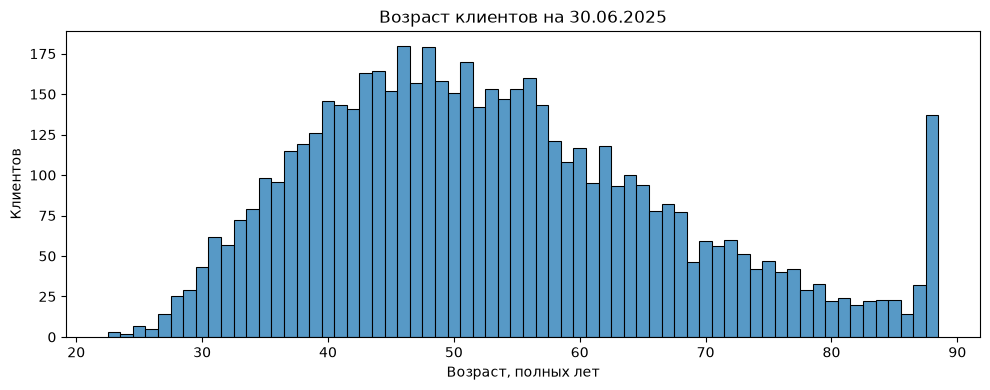

In [41]:
clients['age'] = SNAPSHOT.year - clients['birth_date'].dt.year
birthday_ahead = clients['birth_date'].dt.strftime('%m-%d') > SNAPSHOT.strftime('%m-%d')
clients['age'] = clients['age'] - birthday_ahead.astype(int)

plt.figure(figsize=(10, 4))
sns.histplot(data=clients, x='age', discrete=True)
plt.title('Возраст клиентов на 30.06.2025')
plt.xlabel('Возраст, полных лет')
plt.ylabel('Клиентов')
plt.tight_layout()
plt.show()


У правой границы виден отдельный пик, который не похож на плавное продолжение соседних возрастов. Проверим частоты нескольких верхних возрастов и диапазон дат рождения.


In [42]:
print('Даты рождения:', clients['birth_date'].min(), '—', clients['birth_date'].max())
display(clients['age'].value_counts().sort_index().tail(5))


Даты рождения: 1936-07-26 00:00:00 — 2002-02-13 00:00:00


age
84     23
85     23
86     14
87     32
88    137
Name: count, dtype: int64

Максимальный рассчитанный возраст — 88 лет: таких клиентов 137, тогда как клиентов в возрасте 87 лет — 32. Одна из возможных причин пика — ограничение исходных дат рождения при подготовке выгрузки. По этому распределению причину установить нельзя. Даты сохраняем и отмечаем клиентов с максимальным рассчитанным возрастом отдельным флагом. Если часть дат была заменена ещё в источнике, восстановить прежние значения по этим данным невозможно.

**Доход: распределение и группа малых значений.**

После замены −999 построим распределение известных доходов в том виде, в котором они записаны в выгрузке. Это позволит увидеть общий диапазон и участки с необычными значениями.


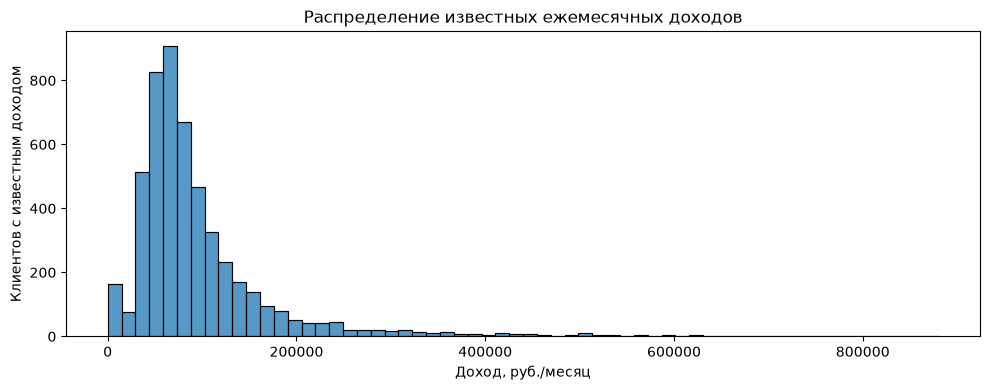

In [43]:
plt.figure(figsize=(10, 4))
sns.histplot(data=clients, x='monthly_income', bins=60)
plt.title('Распределение известных ежемесячных доходов')
plt.xlabel('Доход, руб./месяц')
plt.ylabel('Клиентов с известным доходом')
plt.tight_layout()
plt.show()


Правый хвост растянут, а большинство наблюдений сосредоточено у начала оси. На таком масштабе небольшие значения сливаются. Посмотрим положительные доходы по порядкам величины: применим log10 только для изображения, исходные доходы не меняем.


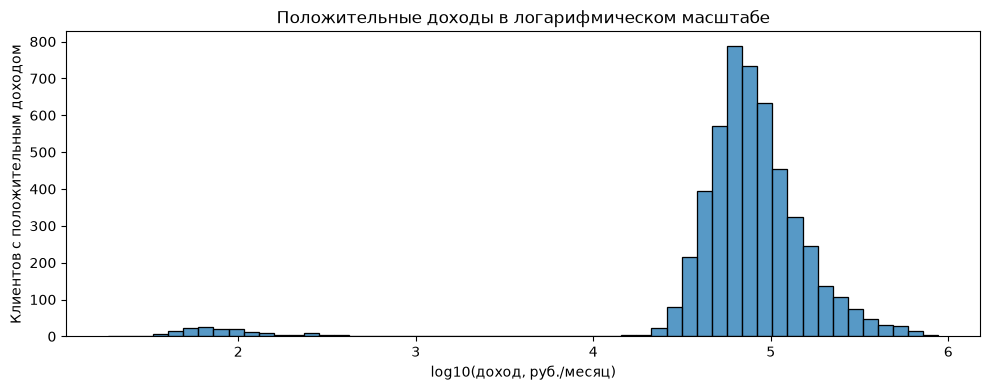

In [44]:
positive_income = clients.loc[clients['monthly_income'] > 0, 'monthly_income'].astype(float)

plt.figure(figsize=(10, 4))
sns.histplot(np.log10(positive_income), bins=55)
plt.title('Положительные доходы в логарифмическом масштабе')
plt.xlabel('log10(доход, руб./месяц)')
plt.ylabel('Клиентов с положительным доходом')
plt.tight_layout()
plt.show()


На логарифмической шкале видна отдельная группа малых положительных значений. Выберем доходы ниже 1000 рублей: это круглая граница в промежутке между двумя группами значений на графике, а не правило автоматического удаления. Посмотрим их число и диапазон внутри сегментов.


In [45]:
low_income = (clients['monthly_income'] > 0) & (clients['monthly_income'] < 1000)
print('Положительных доходов ниже 1000:', low_income.sum(),
      'из', clients['monthly_income'].notna().sum(), 'известных')
display(clients.loc[low_income].groupby('segment')['monthly_income'].agg(['count', 'min', 'median', 'max']))


Положительных доходов ниже 1000: 163 из 5075 известных


,count,min,median,max
segment,,,,
Private,10,244.7,318.85,529.4
Зарплатный,45,36.2,74.3,156.1
Массовый,77,18.4,57.6,165.0
Премиальный,31,72.2,152.5,312.0


Найдены 163 клиента с малым положительным доходом. В таблице видны значения с десятыми долями, тогда как основная группа имеет другой масштаб. Это повод проверить гипотезу: малая группа могла быть записана в тысячах рублей. Одной величины дохода для такого исправления недостаточно — проверим шаг округления и сравним диапазоны и медианы внутри сегментов.

**Проверка гипотезы о тысячах рублей.**


In [46]:
small_income = clients.loc[low_income, 'monthly_income']
ordinary_income = clients.loc[clients['monthly_income'] >= 1000, 'monthly_income']
scaled_income = (small_income * 1000).round(2)

print('Обычных доходов, кратных 100:', (ordinary_income % 100 == 0).sum(),
      'из', len(ordinary_income))
print('Малых доходов с дробной частью:', (small_income % 1 != 0).sum(),
      'из', len(small_income))
print('После ×1000 кратны 100:', (scaled_income % 100 == 0).sum(),
      'из', len(scaled_income))
print('Разрыв между группами:', small_income.max(), '—', ordinary_income.min())


Обычных доходов, кратных 100: 4912 из 4912
Малых доходов с дробной частью: 149 из 163
После ×1000 кратны 100: 163 из 163
Разрыв между группами: 529.4 — 14800.0


Все 4912 обычных доходов кратны 100 рублям. У 149 из 163 малых есть дробная часть; после ×1000 все попадают в ту же сетку округления. Разрыв исходных групп: 529.4–14800.0. Сравним пробный пересчёт с остальными доходами внутри сегментов.


In [47]:
income_check = clients[['segment', 'monthly_income']].copy()
income_check['группа'] = 'Остальные'
income_check.loc[low_income, 'группа'] = 'Малые ×1000'
income_check.loc[low_income, 'monthly_income'] = scaled_income
income_check.groupby(['segment', 'группа'])['monthly_income'].agg(['count', 'min', 'median', 'max'])


count       min    median       max
segment     группа                                          
Private     Малые ×1000     10  244700.0  318850.0  529400.0
            Остальные      196  121500.0  344750.0  880200.0
Зарплатный  Малые ×1000     45   36200.0   74300.0  156100.0
            Остальные     1479   20800.0   78300.0  215700.0
Массовый    Малые ×1000     77   18400.0   57600.0  165000.0
            Остальные     2394   14800.0   61200.0  238900.0
Премиальный Малые ×1000     31   72200.0  152500.0  312000.0
            Остальные      836   52500.0  150000.0  449500.0

После пробного пересчёта диапазоны и медианы внутри сегментов сопоставимы. Сравним форму распределений на одинаковых интервалах; для групп разного размера используем плотность.


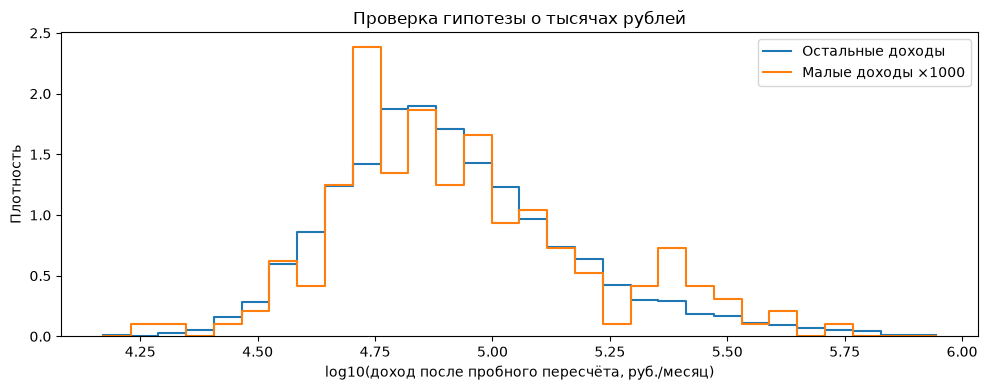

In [48]:
income_bins = np.linspace(np.log10(ordinary_income.min()), np.log10(ordinary_income.max()), 31)

plt.figure(figsize=(10, 4))
sns.histplot(np.log10(ordinary_income.astype(float)), bins=income_bins,
             stat='density', element='step', fill=False, label='Остальные доходы')
sns.histplot(np.log10(scaled_income.astype(float)), bins=income_bins,
             stat='density', element='step', fill=False, label='Малые доходы ×1000')
plt.title('Проверка гипотезы о тысячах рублей')
plt.xlabel('log10(доход после пробного пересчёта, руб./месяц)')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()


**Решение.** После ×1000 распределения совмещаются по масштабу и близки по форме; проверка сегментов и сетки округления поддерживает то же объяснение. Принимаем нормализацию единиц как обоснованное рабочее решение: 163 малых положительных дохода переводим из предполагаемых тысяч рублей в рубли. Подтверждения владельца источника нет, поэтому сохраняем значения до пересчёта и флаг income_scaled, а существенные выводы по доходу позднее проверим также без этих 163 клиентов.

**Приведение к рублям.**


In [49]:
clients['income_before_scale'] = clients['monthly_income']
clients['income_scaled'] = low_income.fillna(False)
clients.loc[clients['income_scaled'], 'monthly_income'] = scaled_income

add_log('monthly_income', 'Часть доходов предположительно записана в тысячах рублей',
        '0<income_before_scale<1000; income_scaled=True', clients['income_scaled'].sum(),
        '18.4–529.4 в исходной записи', 'нормализация единиц', '18400–529400 руб./месяц',
        'После ×1000 совпадает шаг округления; диапазоны, медианы по сегментам и форма гистограмм сопоставимы. Пересчёт принят как рабочее предположение')
print('Доходов приведено к рублям:', clients['income_scaled'].sum())
print('Медиана до / после:', clients['income_before_scale'].median(), '/', clients['monthly_income'].median())
print('Среднее до / после:', round(clients['income_before_scale'].mean(), 2),
      '/', round(clients['monthly_income'].mean(), 2))


Доходов приведено к рублям: 163
Медиана до / после: 74100.0 / 76000.0
Среднее до / после: 96416.25 / 99819.59


Пересчитаны доходы 163 клиентов. Медиана: 74100 → 76000 руб.; среднее: 96416.25 → 99819.59 руб. `income_before_scale` хранит значение после замены −999, но до пересчёта, `income_scaled` — флаг. Пропуски не заполнялись. Доходные различия позднее проверим без этих клиентов.

**Высокие доходы и межквартильный размах.** После приведения единиц сравним доходы по сегментам: медиану, разброс и отдельные высокие значения.


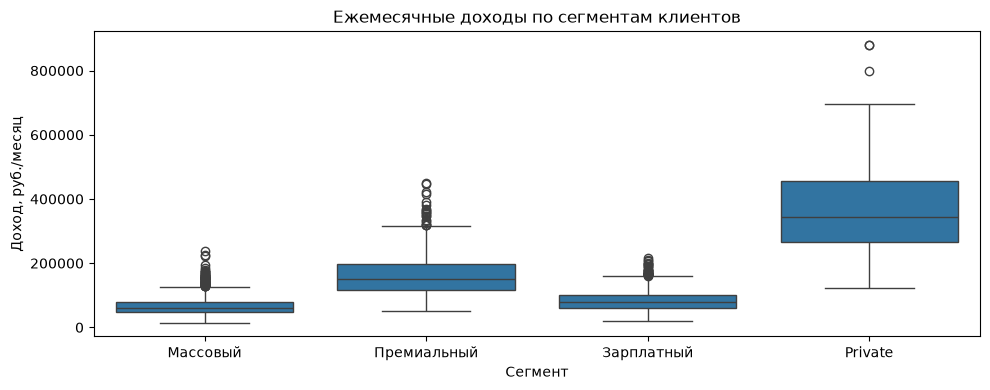

In [50]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=clients, x='segment', y='monthly_income')
plt.title('Ежемесячные доходы по сегментам клиентов')
plt.xlabel('Сегмент')
plt.ylabel('Доход, руб./месяц')
plt.tight_layout()
plt.show()


У премиального сегмента и Private доходы в целом выше, чем у массового и зарплатного. Поэтому часть больших значений может быть связана с составом клиентов. Сам график не подтверждает достоверность каждой записи.

Для дополнительной проверки используем межквартильный размах (МКР): это разница Q3 − Q1, где Q1 и Q3 ограничивают средние 50% значений. Посчитаем доходы ниже Q1 − 1,5 МКР и выше Q3 + 1,5 МКР. Выход за эти границы сам по себе не означает ошибку.

Квартили во всех проверках рассчитываем линейной интерполяцией pandas (`interpolation='linear'`): если позиция квартиля лежит между наблюдениями, берём соответствующее промежуточное значение.


In [51]:
income_q1 = clients['monthly_income'].quantile(0.25, interpolation='linear')
income_q3 = clients['monthly_income'].quantile(0.75, interpolation='linear')
income_iqr = income_q3 - income_q1
income_lower = income_q1 - 1.5 * income_iqr
income_upper = income_q3 + 1.5 * income_iqr
income_outlier = ((clients['monthly_income'] < income_lower)
                  | (clients['monthly_income'] > income_upper))

print('Q1:', income_q1, '; Q3:', income_q3, '; МКР:', income_iqr)
print('Границы Q1 − 1,5 МКР и Q3 + 1,5 МКР:', income_lower, '—', income_upper)
print('За границами:', income_outlier.sum(), 'из', clients['monthly_income'].notna().sum())


Q1: 55600.0 ; Q3: 112400.0 ; МКР: 56800.0
Границы Q1 − 1,5 МКР и Q3 + 1,5 МКР: -29600.0 — 197600.0
За границами: 408 из 5075


Правило 1,5 МКР выделяет только высокие доходы: нижняя граница отрицательная и не отделяет необычные малые положительные значения. Доходы заметно различаются по сегментам, поэтому превышение общей верхней границы само по себе не доказывает ошибку. При выборе обработки учитываем и эти различия.

**Решения по необычным значениям.**

Даты рождения и доходы после пересчёта сохраняем: конкретных оснований заменить высокие значения нет. Клиентов с максимальным рассчитанным возрастом отмечаем флагом `age_upper_flag`, чтобы при дальнейшем отборе проверить результат без этой группы.

Отрицательные суммы возвратов также сохраняем: в аудите знак согласовался со статусом. Суммы операций рассмотрим в разделе 5 после фильтров периода и состава клиентов, отдельно для одной валюты.


In [52]:
clients['age_upper_flag'] = clients['age'] == clients['age'].max()

add_log('age, age_upper_flag, income_missing_raw, score_missing, income_invalid, login_invalid, income_before_scale, income_scaled',
        'Добавлены клиентские расчётные признаки', 'Все уникальные клиенты', len(clients),
        'Расчётных полей нет', 'добавлено', 'Возраст, флаги качества и доход до нормализации единиц',
        'Отделить исходную пустоту от ошибочных значений и сохранить признаки для проверок')


### 3.5. Фильтры перед расчётом активности

`clean` сохранит все статусы и валюты периода задания для клиентов справочника, `success` — успешные положительные операции для частоты. После каждого фильтра записываем размер таблицы в воронку.

**Период задания.** Оставляем даты с 01.01.2024 включительно до 01.07.2025 не включительно, включая весь последний день июня.


In [53]:
valid_date = (transactions['txn_datetime'] >= START) & (transactions['txn_datetime'] < END)
n = (~valid_date).sum()
add_log('txn_datetime', 'Операции вне периода задания', 'Дата <2024-01-01 или >=2025-07-01', n,
        'Вне заявленных 18 месяцев', 'исключено', 'Период 2024-01 .. 2025-06',
        'Соблюсти одинаковые временные границы исследования')
transactions = transactions.loc[valid_date].copy()
funnel_rows.append({'этап': 'В пределах периода', 'строк': len(transactions)})
print('Исключено операций вне периода:', n)
print('Осталось операций:', len(transactions))


Исключено операций вне периода: 82
Осталось операций: 625915


Исключено 82 уникальных операций вне периода задания. Осталось 625915. Следующий фильтр применяется уже к этим строкам, поэтому количества из сырого аудита нельзя автоматически подставлять в воронку.

**Наличие анкеты в справочнике.**

В разделе 2.4 найдены операции клиентов вне справочника действующих клиентов. Для них нет анкетных признаков и согласия в выданных данных. Ограничиваем анализ охватом справочника; это не означает, что сами операции ошибочны.


In [54]:
known_client = transactions['client_id'].isin(clients['client_id'])
n = (~known_client).sum()
add_log('client_id', 'Операции клиентов вне справочника', f'client_id отсутствует в clients после фильтра периода; ID вне справочника: {outside_registry_n}; число уникальных ID сырого файла', n,
        'Нет анкеты клиента', 'исключено', 'Только клиенты справочника',
        'Исследуем действующих клиентов из справочника; только для них доступны анкетные признаки и сведения о согласии')
transactions = transactions.loc[known_client].copy()
funnel_rows.append({'этап': 'Есть клиент в справочнике', 'строк': len(transactions)})
print('Исключено операций без анкеты после фильтра периода:', n)
print('Осталось операций:', len(transactions))


Исключено операций без анкеты после фильтра периода: 29140
Осталось операций: 596775


На шаге исключены 29140 операций, осталось 596775. Сравнивать эту потерю нужно с предыдущим шагом воронки. Клиентов без операций сохраняем в `clients`.

**Присоединение анкет и месяц операции.** В `clients` одна строка на ID. Проверяем отношение «много операций — один клиент», чтобы объединение не размножило строки, и выделяем месяц операции.


In [55]:
clean = transactions.merge(clients, on='client_id', how='left', validate='many_to_one')
clean['month'] = clean['txn_datetime'].dt.to_period('M').astype(str)
add_log('client_id, анкетные признаки, month', 'Подготовка единой аналитической таблицы операций',
        'Все операции после фильтров периода и охвата; many_to_one', len(clean),
        'Поля операций без анкеты и отдельного месяца', 'объединено',
        'Добавлены признаки клиента и месяц YYYY-MM; число операций сохранено',
        'Для помесячной группировки и анализа по характеристикам клиента')
print('Строк до объединения:', len(transactions), '; после:', len(clean))


Строк до объединения: 596775 ; после: 596775


После объединения 596775 строк, в справочнике — 5659 клиентов, включая клиентов без операций.

**Операции для расчёта частоты.** Выделяем успешные операции с положительной суммой; `clean` сохраняет все статусы. Полное определение показателя — в разделе 6.


In [56]:
success = clean.loc[(clean['status'] == 'успешно') & (clean['amount'] > 0)].copy()
funnel_rows.append({'этап': 'Успешные положительные: расчёт частоты', 'строк': len(success)})
add_log('status, amount', 'Выделение успешных положительных операций для частоты',
        "Строки clean вне условия status='успешно' и amount>0", len(clean) - len(success),
        'Все статусы', 'фильтр метрики', 'В success только успешные положительные; clean сохранена',
        'Считаем факты успешного использования; отказ и возврат не добавляют новую успешную оплату или перевод')
print('Операций для расчёта частоты:', len(success))
print('Строк всех статусов в clean:', len(clean))


Операций для расчёта частоты: 577837
Строк всех статусов в clean: 596775


Для частоты выделены 577837 операций. Остальные 18938 строк остаются в `clean`. Успешная операция с последующим возвратом остаётся фактом использования: связать её с возвратом по выданным полям нельзя.

**Воронка операций.** Последняя строка — фильтр метрики, предыдущие — очистка. Потери каждого шага считаются относительно предыдущего.


In [57]:
operation_funnel = pd.DataFrame(funnel_rows)
operation_funnel['исключено на шаге'] = operation_funnel['строк'].shift(1) - operation_funnel['строк']
operation_funnel['потери шага, %'] = (operation_funnel['исключено на шаге']
                                    / operation_funnel['строк'].shift(1) * 100)
operation_funnel.round(2)


,этап,строк,исключено на шаге,"потери шага, %"
0,Сырые операции,627497,NaN,NaN
1,После полных дублей,626214,1283.0,0.20
2,Один txn_id — одна операция,625997,217.0,0.03
3,В пределах периода,625915,82.0,0.01
4,Есть клиент в справочнике,596775,29140.0,4.66
5,Успешные положительные: расчёт частоты,577837,18938.0,3.17


Больше всего операций исключено из-за отсутствия клиента в справочнике. Необычные доходы и возраст не привели к удалению анкет. Поэтому дальнейшая динамика относится к клиентам справочника, а не ко всем ID исходного файла операций.

**Итоговые проверки препроцессинга.**

Проверим ключи, период и отсутствие размножения строк при присоединении анкет. Эти проверки должны остановить выполнение, если подготовленная таблица нарушает выбранные правила.


In [58]:
assert clients['client_id'].is_unique
assert clean['txn_id'].is_unique
assert len(clean) == len(transactions)
assert clean['client_id'].isin(clients['client_id']).all()
assert (clean['txn_datetime'] >= START).all()
assert (clean['txn_datetime'] < END).all()
print('Проверки прошли:', len(clients), 'клиентов,', len(clean), 'операций всех статусов')


Проверки прошли: 5659 клиентов, 596775 операций всех статусов


**Результат препроцессинга.** Сохранены 5659 клиентов и 596775 операций, для частоты — 577837 операций. Противоречия и обработки отмечены флагами, пропуски сохранены. Для 163 доходов выполнено рабочее приведение к рублям с сохранением прежнего значения. Возраст и доходы не обрезаны. Все решения внесены в журнал.

## 4. Журнал изменений

Одна строка журнала соответствует одному решению: поля, проблема, охват, число затронутых строк, исходное значение, действие, результат и основание. `scope` задаёт таблицу и шаг, к которым относится `n_rows`. Разные решения могут затрагивать одни строки, поэтому их количества не складываем. Покажем журнал и число решений каждого типа.


In [59]:
cleaning_log = pd.DataFrame(log_rows, columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])
print('Решений в журнале:', len(cleaning_log))
print('Строк с незаполненными полями:', cleaning_log.isna().any(axis=1).sum())
display(cleaning_log)

cleaning_log['action'].value_counts()


Решений в журнале: 19
Строк с незаполненными полями: 0


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,clients,Полные дубли,Повторные строки по всем полям clients_raw,40,Несколько одинаковых строк,удалено,Одна копия строки,Не учитывать одну анкету несколько раз
1,transactions,Полные дубли,Повторные строки по всем полям transactions_raw,1283,Несколько одинаковых строк,удалено,Одна копия строки,Не учитывать одну операцию несколько раз
2,time_missing,В части записей источник содержит только дату,Все операции после удаления полных дублей,626214,Отдельного признака точности нет,добавлено,"True, если исходное время отсутствует",Отличать техническое 00:00 после преобразовани...
3,"txn_id, txn_datetime",Разная точность записи одной операции,Повторные txn_id: совпали календарный день и о...,217,Дата и дата со временем,удалено,Удалена только версия без времени,Одна операция учитывается один раз; более точн...
4,"birth_date, registration_date, card_open_date,...",Приведение клиентских полей к нужным типам,Все строки clients после удаления полных дублей,5674,"Строки; форматы дат {'birth_date': '%Y-%m-%d',...",преобразовано,Даты — datetime; доход и оценка — числа,"Для сравнения дат, расчёта возраста и числовых..."
5,"txn_datetime, amount",Приведение полей операций к нужным типам,Все уникальные операции после разрешения версий,625997,ISO-дата строкой; сумма строкой с десятичной з...,преобразовано,Дата — datetime; сумма — число в исходной валюте,Для выделения месяца и числовых проверок; неиз...
6,city,Разные написания одного города,Известные варианты из city_map,1629,17 написаний,нормализация,6 городов,Объединены эквивалентные названия из исходного...
7,category,Разные подписи одной категории,Значения из category_map,52234,12 подписей,нормализация,9 категорий,Объединены только эквивалентные названия
8,"client_id, city, segment",Разрешение противоречащих версий анкеты,Все 30 строк версий для 15 client_id после нор...,30,Разные город или сегмент у одного ID,исправлено,Спорные поля — NA; удалено 15 лишних версий; о...,Нет времени обновления: сохраняем согласованны...
9,category_mcc_conflict,Контроль расхождений категории и MCC,Все уникальные операции; расхождение у 1615 из...,625997,Флага расхождения нет,добавлено,Добавлен флаг; исходные category и MCC сохранены,Для основного анализа выбираем category; без э...


action
удалено                3
добавлено              3
преобразовано          2
нормализация           2
заменено               2
исключено              2
исправлено             1
оставлено              1
нормализация единиц    1
объединено             1
фильтр метрики         1
Name: count, dtype: int64

Дальнейшие расчётные признаки и отбор кампании также включаем в журнал; итоговую таблицу соберём перед сохранением.

## 5. Разведочный анализ

Опишем подготовленные данные, затем сравним активность по месяцам, каналам, категориям и признакам клиентов. Распределения возраста и дохода рассмотрены в разделе 3; здесь приведём их основные статистики. Доход используем после пересчёта единиц, сохраняя возможность проверки без пересчитанных записей.

### 5.1. Количественные признаки

**Возраст и доход.** Распределения рассмотрены в разделе 3. Сопоставим среднее и стандартное отклонение с медианой и МКР. Возраст описывает весь справочник, доход — клиентов с известным значением.


In [60]:
age_iqr = clients['age'].quantile(0.75, interpolation='linear') - clients['age'].quantile(0.25, interpolation='linear')
print('МКР возраста, лет:', age_iqr)
clients['age'].describe()


МКР возраста, лет: 19.0


count    5659.000000
mean       53.162043
std        14.092285
min        23.000000
25%        43.000000
50%        51.000000
75%        62.000000
max        88.000000
Name: age, dtype: float64

Средний и медианный возраст близки, но отдельный пик у верхней границы требует сохранять флаг качества. Для дохода покажем те же описательные статистики после пересчёта единиц.


In [61]:
print('МКР дохода, руб./месяц:', income_iqr)
clients['monthly_income'].describe()


МКР дохода, руб./месяц: 56800.0


count          5075.0
mean     99819.586207
std      80533.769096
min           14800.0
25%           55600.0
50%           76000.0
75%          112400.0
max          880200.0
Name: monthly_income, dtype: Float64

Высокие доходы поднимают среднее относительно медианы. Типичный уровень описываем медианой, разброс — МКР.

**Сумма успешной операции внутри одной валюты.** Рассмотрим положительные RUB-операции. Частота использования по-прежнему включает все валюты.


In [62]:
rub_success = success.loc[success['currency'] == 'RUB']
amount_q1, amount_q3 = rub_success['amount'].quantile([0.25, 0.75], interpolation='linear')
amount_iqr = amount_q3 - amount_q1
print('МКР суммы, руб.:', round(amount_iqr, 2))
rub_success['amount'].describe()


МКР суммы, руб.: 1808.01


count       575507.0
mean      1915.44697
std      2629.074743
min              4.9
25%           492.07
50%          1093.38
75%          2300.08
max         82045.28
Name: amount, dtype: Float64

Средняя сумма существенно выше медианы: крупные операции заметно влияют на неё. Посмотрим распределение с логарифмической осью, чтобы различить малые платежи и основной массив, затем отдельно проверим малые и высокие суммы.


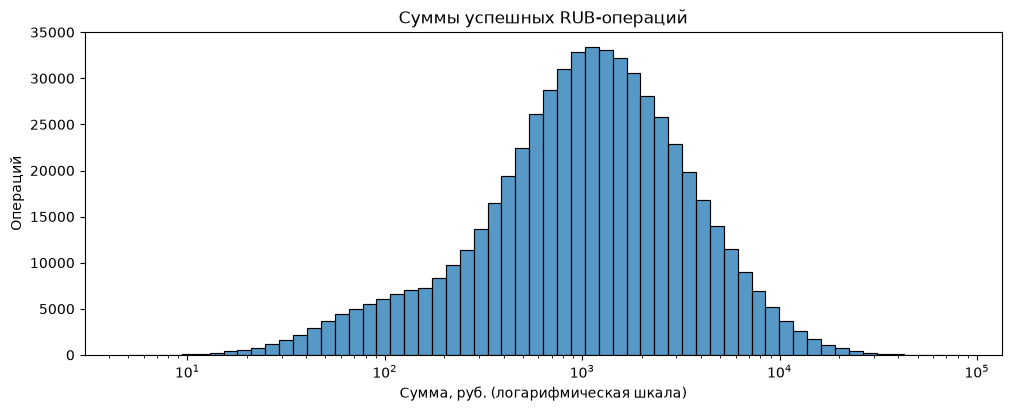

In [63]:
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
sns.histplot(data=rub_success, x='amount', log_scale=True, bins=60, ax=ax)
ax.set_title('Суммы успешных RUB-операций')
ax.set_xlabel('Сумма, руб. (логарифмическая шкала)')
ax.set_ylabel('Операций')
plt.show()


**Малые платежи.** Проверим категории всех платежей меньше 100 рублей. Это диагностическая граница для описания, а не правило удаления.


In [64]:
small = rub_success['amount'] < 100
print('Успешных RUB-платежей меньше 100:', small.sum(), 'из', len(rub_success))
small_categories = rub_success.loc[small].groupby('category')['amount'].agg(n='size', median='median')
small_categories['доля малых платежей, %'] = small_categories['n'] / small.sum() * 100
display(small_categories.sort_values('n', ascending=False).round(2))


Успешных RUB-платежей меньше 100: 32229 из 575507


,n,median,"доля малых платежей, %"
category,,,
Транспорт,30630,59.82,95.04
Онлайн-сервисы,737,81.75,2.29
Связь и интернет,439,81.51,1.36
Продукты,263,84.3,0.82
Аптеки,132,87.44,0.41
Кафе и рестораны,22,82.48,0.07
АЗС,6,86.74,0.02


Из 32229 малых платежей 30630 (95.04%) относятся к транспорту. Это согласуется с оплатой проезда, хотя назначения и тарифа в данных нет. Малые суммы сохраняем.

**Высокие суммы.** Максимум 82045.28 руб., медиана 1093.38 руб. Проверим операции выше Q3 + 1,5 МКР и их категории: это диагностическая граница, а не правило удаления.


In [65]:
amount_upper = amount_q3 + 1.5 * amount_iqr
large_amount = rub_success['amount'] > amount_upper
print('Граница Q3 + 1,5 МКР, руб.:', round(amount_upper, 2))
print('Операций выше границы:', large_amount.sum(), 'из', len(rub_success))
large_categories = rub_success.loc[large_amount].groupby('category')['amount'].agg(
    n='size', median='median', max='max')
display(large_categories.sort_values('n', ascending=False).round(2))


Граница Q3 + 1,5 МКР, руб.: 5012.09
Операций выше границы: 46492 из 575507


,n,median,max
category,,,
Одежда и обувь,25728,7833.46,73504.08
Развлечения и досуг,8404,6919.17,51283.69
АЗС,4959,6522.27,55177.6
Кафе и рестораны,4665,6356.25,82045.28
Продукты,2258,6153.05,31201.7
Аптеки,322,6087.29,74569.44
Связь и интернет,115,6104.04,13961.58
Онлайн-сервисы,41,5886.49,10011.26


У одежды и обуви 25728 из 46492 операций выше общей границы МКР. Оценивать суммы нужно с учётом категории. Ошибку записи не установили, суммы сохраняем. Типичный платёж описываем медианой и МКР; в частоте каждая операция имеет одинаковый вес.

### 5.2. Частоты категориальных признаков

У клиентов считаем уникальные ID, у операций — все строки `clean`, включая отказы и возвраты. Пропуски включены отдельной строкой. Эти таблицы описывают состав данных; частоту использования ниже считаем по `success`.

Статус приложения и тип текущей карты известны на дату среза. «Не указан» означает отсутствие сведений об источнике зарплаты. Для порядковой оценки обслуживания покажем также медиану, моду и число ответивших.


In [66]:
for column in ['segment', 'loyalty_tier', 'card_type', 'has_mobile_app',
               'income_source', 'gender', 'city', 'marketing_opt_in', 'satisfaction_score']:
    counts = clients[column].value_counts(dropna=False)
    print(f'{column}: n = {len(clients)} клиентов')
    display(pd.DataFrame({
        'клиентов': counts,
        'доля клиентов, %': counts / len(clients) * 100,
    }).round(2))

print('Ответивших на опрос:', clients['satisfaction_score'].notna().sum(), 'из', len(clients))
print('Медиана оценки:', clients['satisfaction_score'].median())
print('Мода оценки:', clients['satisfaction_score'].mode().tolist())


segment: n = 5659 клиентов


,клиентов,"доля клиентов, %"
segment,,
Массовый,2829,49.99
Зарплатный,1620,28.63
Премиальный,967,17.09
Private,233,4.12
<NA>,10,0.18


loyalty_tier: n = 5659 клиентов


,клиентов,"доля клиентов, %"
loyalty_tier,,
Базовый,2862,50.57
Серебро,1498,26.47
Золото,1003,17.72
Платина,296,5.23


card_type: n = 5659 клиентов


,клиентов,"доля клиентов, %"
card_type,,
Дебетовая,3917,69.22
Кредитная,1232,21.77
Премиальная,510,9.01


... (9 outputs left out)

,клиентов,"доля клиентов, %"
marketing_opt_in,,
Да,4982,88.04
Нет,677,11.96


satisfaction_score: n = 5659 клиентов


,клиентов,"доля клиентов, %"
satisfaction_score,,
<NA>,3350,59.2
5,661,11.68
4,471,8.32
3,451,7.97
2,433,7.65
1,293,5.18


Ответивших на опрос: 2309 из 5659
Медиана оценки: 3.0
Мода оценки: [5]


Опрос охватывает меньше половины клиентов, причём доля ответивших различается между уровнями лояльности. Поэтому оценки описывают ответивших и могут давать неполную картину удовлетворённости всей базы.


In [67]:
for column in ['status', 'currency', 'channel', 'category']:
    counts = clean[column].value_counts(dropna=False)
    print(f'{column}: n = {len(clean)} операций')
    display(pd.DataFrame({
        'операций': counts,
        'доля операций, %': counts / len(clean) * 100,
    }).round(2))


status: n = 596775 операций


,операций,"доля операций, %"
status,,
успешно,577837,96.83
отклонено,11732,1.97
возврат,7206,1.21


currency: n = 596775 операций


,операций,"доля операций, %"
currency,,
RUB,594371,99.6
EUR,1218,0.2
USD,1186,0.2


channel: n = 596775 операций


,операций,"доля операций, %"
channel,,
Карта,303395,50.84
СБП,108122,18.12
Токен,101598,17.02
Онлайн-банк,83660,14.02


category: n = 596775 операций


,операций,"доля операций, %"
category,,
Продукты,156451,26.22
Кафе и рестораны,77805,13.04
Одежда и обувь,67579,11.32
Транспорт,62638,10.5
АЗС,55523,9.3
Связь и интернет,46333,7.76
Развлечения и досуг,45970,7.7
Аптеки,42822,7.18
Онлайн-сервисы,41654,6.98


Сегменты существенно различаются по размеру, поэтому сравниваем изменение на клиента и показываем размеры групп. Чаще всего операции проходят через «Карту». Каналы рассмотрим отдельно; следующие расчёты используют успешные положительные операции.

### 5.3. Динамика по месяцам

Построим месячную сетку успешных положительных операций всех валют и каналов, включая нулевые месяцы. `base` — средняя частота за 2024, `recent` — за январь–июнь 2025, `activity_loss = base - recent` — потеря операций на клиента в месяц. Положительное значение означает снижение, отрицательное — рост.

Во всех временных и клиентских сравнениях фиксируем клиентов, у которых регистрация и открытие текущей карты не позже 01.01.2024. Проверка раздела 2.4 показала, что более поздняя карта связана с неполным наблюдением базы. Подробное обоснование метрики — в разделе 6.


In [68]:
months = pd.period_range('2024-01', '2025-06', freq='M').astype(str)
monthly = pd.crosstab(success['client_id'], success['month'])
monthly = monthly.reindex(index=clients['client_id'], columns=months, fill_value=0)

full_window = clients['registration_date'].le(START) & clients['card_open_date'].le(START)
full_ids = clients.loc[full_window, 'client_id']
monthly_full = monthly.loc[full_ids]
print('Клиентов в месячной сетке:', len(monthly))
print('Месяцев в сетке:', len(months))
print('Регистрация и текущая карта не позже начала 2024 года:', len(full_ids))


Клиентов в месячной сетке: 5659
Месяцев в сетке: 18
Регистрация и текущая карта не позже начала 2024 года: 4874


**Общая месячная динамика.** Сравним годы на фиксированном составе клиентов. Месяцы без операций включены как нули; отсутствие времени суток не мешает выделить известный месяц операции.


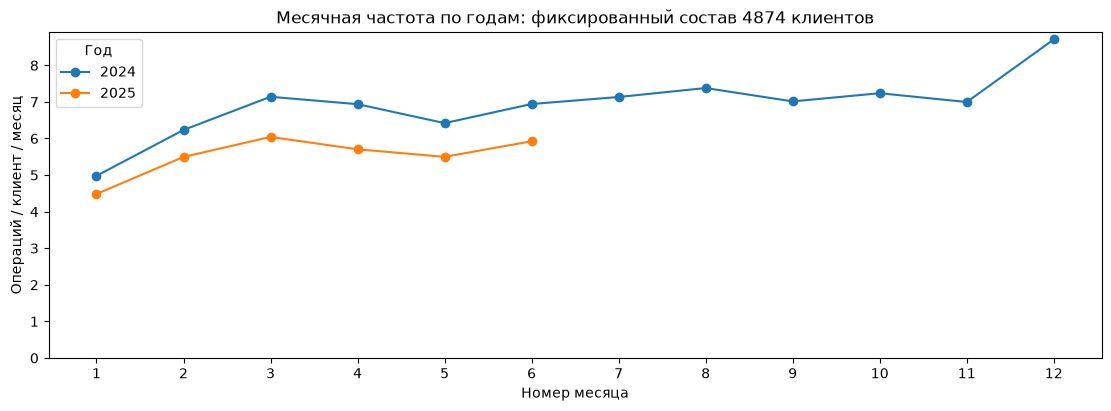

In [69]:
mean_monthly = monthly_full.mean()

fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
ax.plot(range(1, 13), mean_monthly.loc['2024-01':'2024-12'], marker='o', label='2024')
ax.plot(range(1, 7), mean_monthly.loc['2025-01':'2025-06'], marker='o', label='2025')
ax.set_xticks(range(1, 13))
ax.set_ylim(0, None)
ax.set_title(f'Месячная частота по годам: фиксированный состав {len(full_ids)} клиентов')
ax.set_xlabel('Номер месяца')
ax.set_ylabel('Операций / клиент / месяц')
ax.legend(title='Год')
plt.show()


В 2024 году выделяется декабрьский пик, а январь заметно слабее остальных месяцев. Значения первого полугодия 2025 ниже тех же месяцев 2024. Поэтому сравним результат как с годовой базой, так и с одинаковым полугодием: календарный состав окон может влиять на размер разницы.

**Индивидуальные изменения в фиксированном составе.**

Создадим клиентские показатели на основе месячной сетки. Для общего временного ряда и клиентских разрезов используем один и тот же состав. Разница частот определена и при нулевой базе: появление операций даёт рост, отсутствие операций в обоих окнах — нулевое изменение.


In [70]:
profiles = clients.set_index('client_id')
profiles['base'] = monthly.iloc[:, :12].sum(axis=1) / 12
profiles['recent'] = monthly.iloc[:, 12:].sum(axis=1) / 6
profiles['season_base'] = monthly.iloc[:, :6].sum(axis=1) / 6
# Разность целых счётчиков сохраняет точный ноль при одинаковой частоте.
profiles['activity_loss'] = (monthly.iloc[:, :12].sum(axis=1)
                             - 2 * monthly.iloc[:, 12:].sum(axis=1)) / 12
profiles['full_history'] = (profiles['registration_date'].le(START)
                             & profiles['card_open_date'].le(START))
cohort = profiles.loc[profiles['full_history']].copy()

add_log('base, recent, season_base, activity_loss, full_history',
        'Подготовка месячных показателей активности',
        'Все клиенты profiles; сравнение — регистрация и текущая карта к 01.01.2024', len(profiles),
        'Число операций по месяцам', 'добавлено',
        f'Месячные частоты и их разница; сравниваются {len(cohort)} клиентов, вне сравнения {len(profiles)-len(cohort)} без полного базового окна',
        'Сопоставить окна разной длины в одном составе, включая месяцы и клиентов без операций')
print('Клиентов в сравнении:', len(cohort))

old_window = profiles['registration_date'].le(START)
new_card = old_window & ~profiles['full_history']
history_comparison = pd.DataFrame([
    {'состав': label, 'клиентов': int(mask.sum()),
     'рост: клиентов': int(profiles.loc[mask, 'activity_loss'].lt(0).sum()),
     'рост, %': 100 * profiles.loc[mask, 'activity_loss'].lt(0).mean(),
     'средняя потеря': profiles.loc[mask, 'activity_loss'].mean()}
    for label, mask in [('Только ранняя регистрация', old_window),
                        ('Из них текущая карта после начала базы', new_card),
                        ('Ранняя регистрация и старая карта', profiles['full_history'])]
])
display(history_comparison.round(3))


Клиентов в сравнении: 4874


,состав,клиентов,рост: клиентов,"рост, %",средняя потеря
0,Только ранняя регистрация,5547,1901,34.271,1.070
1,Из них текущая карта после начала базы,673,647,96.137,-1.336
2,Ранняя регистрация и старая карта,4874,1254,25.728,1.403


**Состав сравнения.** Из 5547 клиентов с ранней регистрацией исключены 673 с более поздней текущей картой: у 647 из них наблюдаемый рост, поэтому неполный базовый период искажал общее сравнение. Остаются 4874 клиента. Признак `full_history` далее означает выполнение обоих условий по датам; это рабочее условие доступности окна, а не подтверждение каждой операции.

**Сравнение одинаковых полугодий.** Сопоставим средние частоты за весь 2024, январь–июнь 2024 и январь–июнь 2025 на этом составе.


In [71]:
period_comparison = pd.DataFrame({
    'период': ['2024 год', 'январь–июнь 2024', 'январь–июнь 2025'],
    'операций / клиент / месяц': [cohort['base'].mean(), cohort['season_base'].mean(), cohort['recent'].mean()],
    'клиентов': len(cohort),
})
display(period_comparison.round(3))

overall_loss = cohort['base'].mean() - cohort['recent'].mean()
season_loss = cohort['season_base'].mean() - cohort['recent'].mean()
print('Потеря к среднему месяцу 2024, операций/клиент/месяц:', round(overall_loss, 3))
print('Потеря к тем же месяцам 2024, операций/клиент/месяц:', round(season_loss, 3))


,период,операций / клиент / месяц,клиентов
0,2024 год,6.927,4874
1,январь–июнь 2024,6.442,4874
2,январь–июнь 2025,5.524,4874


Потеря к среднему месяцу 2024, операций/клиент/месяц: 1.403
Потеря к тем же месяцам 2024, операций/клиент/месяц: 0.918


**Проверка объяснения: активных клиентов стало меньше или они совершают меньше операций?**

Общая частота может уменьшиться при сокращении доли активных клиентов или частоты среди активных. По приёму декомпозиции из третьей недели покажем обе составляющие рядом с результатом. Сравним одинаковые полугодия на фиксированном составе. Активным считаем клиента с хотя бы одной успешной положительной операцией в конкретном месяце.

Общая частота = доля активных клиент-месяцев × операций на активный клиент-месяц. Во втором множителе каждое наблюдение — активная пара «клиент–месяц»; это не среднее только по клиентам, совершавшим операции весь период.


In [72]:
activity_components = []
for period, columns in [('Янв–июнь 2024', months[:6]), ('Янв–июнь 2025', months[12:])]:
    period_counts = monthly.loc[cohort.index, columns]
    active_client_months = period_counts.gt(0).sum().sum()
    operations = period_counts.sum().sum()
    activity_components.append({
        'период': period,
        'общая частота': operations / period_counts.size,
        'доля активных': active_client_months / period_counts.size,
        'частота среди активных': operations / active_client_months,
    })
activity_components = pd.DataFrame(activity_components).set_index('период')
assert np.allclose(activity_components['общая частота'],
                   activity_components['доля активных'] * activity_components['частота среди активных'])
activity_components.round(3)

print('Показатели графика в процентах и операциях:')
display(activity_components.assign(**{'доля активных': activity_components['доля активных'] * 100}).round(2))


Показатели графика в процентах и операциях:


,общая частота,доля активных,частота среди активных
период,,,
Янв–июнь 2024,6.44,97.74,6.59
Янв–июнь 2025,5.52,91.82,6.02


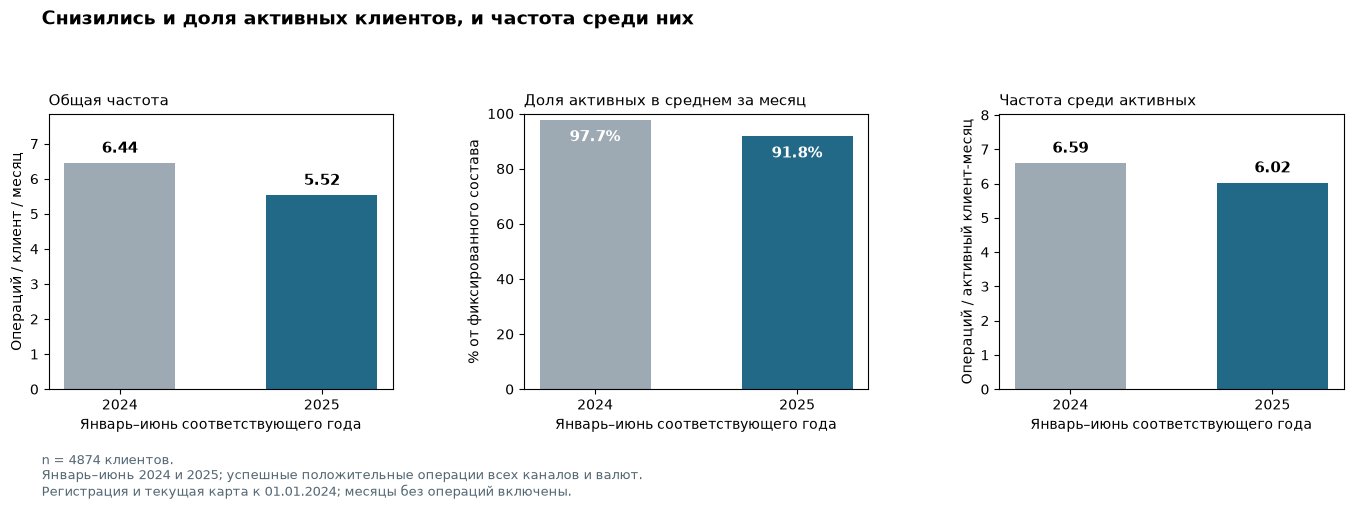

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5.2))
component_panels = [
    ('общая частота', 'Общая частота', 'Операций / клиент / месяц'),
    ('доля активных', 'Доля активных в среднем за месяц', '% от фиксированного состава'),
    ('частота среди активных', 'Частота среди активных', 'Операций / активный клиент-месяц'),
]
for ax, (column, title, units) in zip(axes, component_panels):
    values = activity_components[column].copy()
    if column == 'доля активных':
        values = values * 100
    bars = ax.bar(['2024', '2025'], values, color=['#9daab3', '#226887'], width=.55)
    ax.bar_label(bars, labels=[f'{v:.1f}%' if column == 'доля активных' else f'{v:.2f}' for v in values],
                 padding=-18 if column == 'доля активных' else 5,
                 color='white' if column == 'доля активных' else 'black',
                 fontsize=11, fontweight='bold')
    ax.set_title(title, loc='left', fontsize=11)
    ax.set_xlabel('Январь–июнь соответствующего года')
    ax.set_ylabel(units)
    ax.set_ylim(0, 100 if column == 'доля активных' else values.max() * 1.22)
    ax.grid(axis='x', visible=False)
fig.suptitle('Снизились и доля активных клиентов, и частота среди них',
             x=.06, ha='left', fontsize=14, fontweight='bold', y=.97)
fig.subplots_adjust(top=.77, bottom=.24, left=.065, right=.99, wspace=.38)
fig.text(.06, .035,
    f'n = {len(cohort)} клиентов.\n'
    'Январь–июнь 2024 и 2025; успешные положительные операции всех каналов и валют.\n'
    'Регистрация и текущая карта к 01.01.2024; месяцы без операций включены.',
    fontsize=9, color='#536773')
plt.show()


Доля активных клиент-месяцев снизилась с 97,74% до 91,82%, а число операций на активный клиент-месяц — с 6,59 до 6,02. На полном базовом окне уменьшились обе составляющие общей частоты. Состав активных меняется по месяцам; разложение описывает результат, но не устанавливает причины поведения.

Средняя частота уменьшается и относительно всего 2024 года, и относительно того же полугодия. Во втором случае потеря меньше: календарный состав окон влияет на величину результата, но не снимает спад.

**Направления индивидуального изменения.** Посчитаем направления изменений. Отдельно отличим прекращение наблюдаемых операций после положительной базы от отсутствия операций в обоих окнах.


In [74]:
assert monthly.sum().sum() == len(success)
assert np.isfinite(cohort['activity_loss']).all()

change_summary = pd.DataFrame({
    'изменение': ['Снижение', 'Без изменения', 'Рост'],
    'клиентов': [(cohort['activity_loss'] > 0).sum(), (cohort['activity_loss'] == 0).sum(),
                 (cohort['activity_loss'] < 0).sum()],
})
change_summary['доля, %'] = change_summary['клиентов'] / len(cohort) * 100
print('Были операции в 2024, нет в первом полугодии 2025:',
      ((cohort['base'] > 0) & (cohort['recent'] == 0)).sum())
print('Нет операций в обоих окнах:', ((cohort['base'] == 0) & (cohort['recent'] == 0)).sum())
display(change_summary.round(2))


Были операции в 2024, нет в первом полугодии 2025: 3
Нет операций в обоих окнах: 0


,изменение,клиентов,"доля, %"
0,Снижение,3549,72.81
1,Без изменения,71,1.46
2,Рост,1254,25.73


Снижение встречается чаще роста. Рост у 25,7% клиентов; после положительной базы операции полностью отсутствуют у 3. Для большинства случаев исследуем уменьшение частоты.

**Влияние окна сравнения.** Сопоставим направление изменения при годовой базе и одинаковых полугодиях. В таблице `True` — снижение, `False` — его отсутствие. Нулевые базы сохраняем.


In [75]:
display(pd.crosstab(cohort['recent'] < cohort['base'],
            cohort['recent'] < cohort['season_base'],
            rownames=['Снижение к 2024 году'],
            colnames=['Снижение к январю–июню 2024']))


Снижение к январю–июню 2024,False,True
Снижение к 2024 году,,
False,1267,58
True,518,3031


Только к годовой базе снижение есть у 518 клиентов, только к полугодию — у 58. При описании групп дополнительно рассмотрим одинаковые месяцы и помесячный характер изменения.

### 5.4. Разрезы и связи

**Динамика каналов.** Для одинаковых месяцев покажем разницу операций 2024 и 2025 на клиента фиксированного состава. Положительное значение — потеря, отрицательное — рост; ноль означает прежнюю частоту.


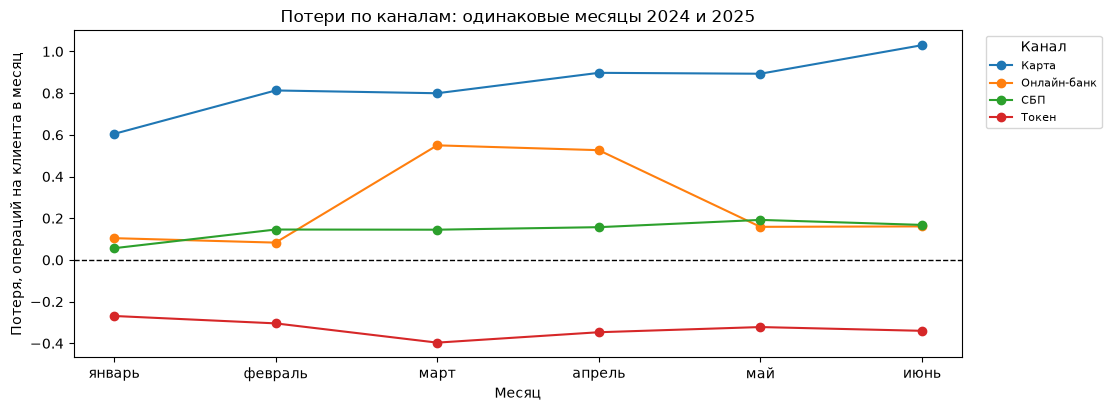

In [76]:
full_success = success.loc[success['client_id'].isin(full_ids)]
channel_monthly = pd.crosstab(full_success['month'], full_success['channel']).reindex(months, fill_value=0)
base_channels = channel_monthly.loc['2024-01':'2024-06'].reset_index(drop=True)
recent_channels = channel_monthly.loc['2025-01':'2025-06'].reset_index(drop=True)
channel_loss = (base_channels - recent_channels) / len(cohort)
channel_loss.index = ['январь', 'февраль', 'март', 'апрель', 'май', 'июнь']

fig, ax = plt.subplots(figsize=(11, 4), layout='constrained')
channel_loss.plot(marker='o', ax=ax)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('Потери по каналам: одинаковые месяцы 2024 и 2025')
ax.set_xlabel('Месяц')
ax.set_ylabel('Потеря, операций на клиента в месяц')
ax.legend(title='Канал', fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.show()


Потеря через «Карту» сохраняется во все шесть месяцев, а «Токен» даёт рост, частично компенсирующий спад других каналов. По описанию задания «Карта» означает оплату физической картой, «Токен» — смартфоном или часами. По общему графику нельзя установить, заменили ли конкретные клиенты один способ другим.

У «Онлайн-банка» выделяется провал в марте–апреле. Сравним его с маем–июнем в тех же единицах.


In [77]:
online_marapr_loss = (channel_monthly.loc['2024-03':'2024-04', 'Онлайн-банк'].sum()
                     - channel_monthly.loc['2025-03':'2025-04', 'Онлайн-банк'].sum()) / 2 / len(cohort)
online_mayjun_loss = (channel_monthly.loc['2024-05':'2024-06', 'Онлайн-банк'].sum()
                     - channel_monthly.loc['2025-05':'2025-06', 'Онлайн-банк'].sum()) / 2 / len(cohort)
pd.DataFrame({
    'месяцы': ['март–апрель', 'май–июнь'],
    'потеря к тем же месяцам 2024, операций/клиент/месяц': [online_marapr_loss, online_mayjun_loss],
}).round(3)


,месяцы,"потеря к тем же месяцам 2024, операций/клиент/месяц"
0,март–апрель,0.538
1,май–июнь,0.160


**Проверка альтернативного объяснения: увеличилась ли доля отказов?** Если снижение успешных операций «Онлайн-банка» связано с ростом зарегистрированных отказов, в марте–апреле 2025 ожидаем увидеть увеличение доли отклонённых операций. Сопоставим те же месяцы 2024 и 2025 на фиксированном составе клиентов. Знаменатель доли отказов — успешные плюс отклонённые операции; возврат не является новой попыткой и в этот знаменатель не входит. Левый график покажет, изменилось ли само число зарегистрированных попыток, правый — какая их доля завершилась отказом.


In [78]:
online_attempts = clean.loc[
    clean['client_id'].isin(cohort.index)
    & clean['channel'].eq('Онлайн-банк')
    & clean['status'].isin(['успешно', 'отклонено'])
    & clean['txn_datetime'].dt.month.le(6)
].copy()
online_attempts['year'] = online_attempts['txn_datetime'].dt.year
online_attempts['month_no'] = online_attempts['txn_datetime'].dt.month
online_attempts['declined'] = online_attempts['status'].eq('отклонено')
online_status = online_attempts.groupby(['year', 'month_no']).agg(
    attempts=('txn_id', 'size'), declined=('declined', 'sum'))
online_status['attempts_per_client'] = online_status['attempts'] / len(cohort)
online_status['decline_pct'] = 100 * online_status['declined'] / online_status['attempts']

online_spring = online_attempts.loc[online_attempts['month_no'].isin([3, 4])]
online_spring = online_spring.groupby('year').agg(
    attempts=('txn_id', 'size'), declined=('declined', 'sum'))
online_spring['successful'] = online_spring['attempts'] - online_spring['declined']
online_spring['decline_pct'] = 100 * online_spring['declined'] / online_spring['attempts']
spring_attempt_change = 100 * (online_spring.loc[2025, 'attempts'] / online_spring.loc[2024, 'attempts'] - 1)
spring_decline_change = online_spring.loc[2025, 'decline_pct'] - online_spring.loc[2024, 'decline_pct']

display(online_spring.round(3))
print('Изменение попыток, %:', round(spring_attempt_change, 1))
print('Изменение доли отказов, п.п.:', round(spring_decline_change, 2))


,attempts,declined,successful,decline_pct
year,,,,
2024,10242,201,10041,1.963
2025,4887,91,4796,1.862


Изменение попыток, %: -52.3
Изменение доли отказов, п.п.: -0.1


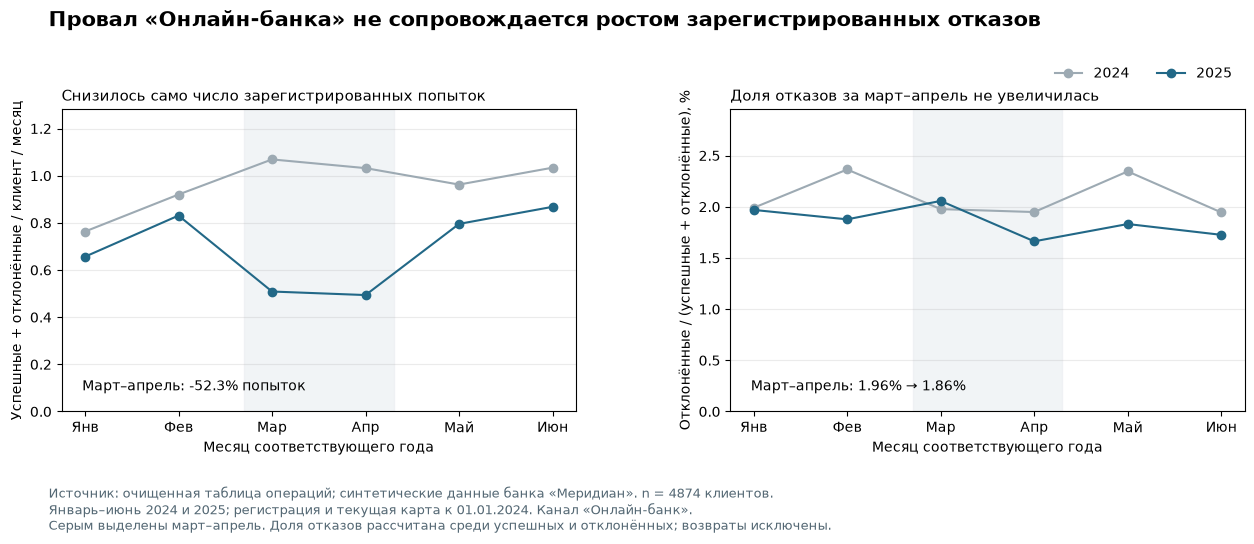

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for year, color in [(2024, '#9daab3'), (2025, '#226887')]:
    part = online_status.loc[year]
    axes[0].plot(part.index, part['attempts_per_client'], 'o-', color=color, label=str(year))
    axes[1].plot(part.index, part['decline_pct'], 'o-', color=color, label=str(year))
for ax in axes:
    ax.set_xticks(range(1, 7), ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн'])
    ax.set_xlabel('Месяц соответствующего года')
    ax.axvspan(2.7, 4.3, color='#e9edf0', alpha=.6, zorder=0)
    ax.grid(axis='y', alpha=.25)
    ax.grid(axis='x', visible=False)
axes[0].set_title('Снизилось само число зарегистрированных попыток', loc='left', fontsize=11)
axes[0].set_ylabel('Успешные + отклонённые / клиент / месяц')
axes[0].set_ylim(0, online_status['attempts_per_client'].max() * 1.2)
axes[0].text(.04, .07, f'Март–апрель: {spring_attempt_change:.1f}% попыток', transform=axes[0].transAxes)
axes[1].set_title('Доля отказов за март–апрель не увеличилась', loc='left', fontsize=11)
axes[1].set_ylabel('Отклонённые / (успешные + отклонённые), %')
axes[1].set_ylim(0, online_status['decline_pct'].max() * 1.25)
axes[1].text(.04, .07, f'Март–апрель: {online_spring.loc[2024, "decline_pct"]:.2f}% → '
             f'{online_spring.loc[2025, "decline_pct"]:.2f}%', transform=axes[1].transAxes)
fig.suptitle('Провал «Онлайн-банка» не сопровождается ростом зарегистрированных отказов',
             x=.06, y=.98, ha='left', fontsize=15, fontweight='bold')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(.98, .90), ncols=2, frameon=False)
fig.subplots_adjust(top=.80, bottom=.25, left=.07, right=.98, wspace=.30)
fig.text(.06, .035,
    f'Источник: очищенная таблица операций; синтетические данные банка «Меридиан». n = {len(cohort)} клиентов.\n'
    'Январь–июнь 2024 и 2025; регистрация и текущая карта к 01.01.2024. Канал «Онлайн-банк».\n'
    'Серым выделены март–апрель. Доля отказов рассчитана среди успешных и отклонённых; возвраты исключены.',
    fontsize=9, color='#536773')
plt.show()


**Результат проверки.** В марте–апреле число успешных операций снизилось с 10041 до 4796, а число зарегистрированных попыток — с 10242 до 4887 (−52,3%). Доля отказов изменилась с 1,96% до 1,86% (−0,10 п.п.). Рост зарегистрированных отказов не объясняет провал. Попытки, не попавшие в выгрузку, не наблюдаются.

В мае–июне потеря «Онлайн-банка» заметно меньше, чем в марте–апреле. Поэтому глубину временного провала нельзя переносить на всё полугодие. Без журнала событий его причину установить нельзя.

Разложим основную потерю относительно всего 2024 года. `base` и `recent` — средние месячные частоты, `activity_loss` — их разница на клиента. Ранее сравнивали одинаковые месяцы.


In [80]:
channel_change = pd.DataFrame({
    'base': channel_monthly.loc['2024-01':'2024-12'].sum() / 12 / len(cohort),
    'recent': channel_monthly.loc['2025-01':'2025-06'].sum() / 6 / len(cohort),
})
channel_change['activity_loss'] = channel_change['base'] - channel_change['recent']
channel_change.sort_values('activity_loss', ascending=False).round(3)


,base,recent,activity_loss
channel,,,
Карта,3.652,2.552,1.100
Онлайн-банк,1.019,0.680,0.339
СБП,1.240,1.021,0.219
Токен,1.016,1.272,-0.256


**Проверка на уровне клиентов.** Общий график показывает средние изменения каналов. Проверим отдельно, у скольких клиентов одновременно сокращается «Карта» и растёт «Токен», а также уменьшается ли у них общая частота по всем каналам. Сравним годовую базу и одинаковые полугодия. Доля в последнем столбце рассчитана среди клиентов с сочетанием «Карта ↓, Токен ↑», а не среди всей когорты.


In [81]:
channel_2024 = (success.loc[success['month'] < '2025-01']
                .groupby(['client_id', 'channel']).size().unstack(fill_value=0)
                .reindex(index=cohort.index, columns=channel_monthly.columns, fill_value=0))
channel_h1_2024 = (success.loc[success['month'] <= '2024-06']
                   .groupby(['client_id', 'channel']).size().unstack(fill_value=0)
                   .reindex(index=cohort.index, columns=channel_monthly.columns, fill_value=0))
channel_h1_2025 = (success.loc[success['month'] >= '2025-01']
                   .groupby(['client_id', 'channel']).size().unstack(fill_value=0)
                   .reindex(index=cohort.index, columns=channel_monthly.columns, fill_value=0))

# Сначала разность целых счётчиков: нулевое изменение останется ровно нулевым.
channel_delta_year = (2 * channel_h1_2025 - channel_2024) / 12
channel_delta_h1 = (channel_h1_2025 - channel_h1_2024) / 6
joint_channel_rows = []
for name, delta in [('2024 год', channel_delta_year),
                    ('Январь–июнь 2024', channel_delta_h1)]:
    same_clients = (delta['Карта'] < 0) & (delta['Токен'] > 0)
    total_declined = delta.sum(axis=1).round(6) < 0
    joint_channel_rows.append({
        'База сравнения': name,
        'Карта ↓, Токен ↑: клиентов': same_clients.sum(),
        'Из них общая частота ↓: клиентов': (same_clients & total_declined).sum(),
        'Доля со снижением общей частоты, %': 100 * total_declined.loc[same_clients].mean(),
    })
joint_channel_check = pd.DataFrame(joint_channel_rows).set_index('База сравнения')
display(joint_channel_check.round(1))
paired_n = int(joint_channel_check.loc['Январь–июнь 2024', 'Карта ↓, Токен ↑: клиентов'])
paired_decline_n = int(joint_channel_check.loc['Январь–июнь 2024', 'Из них общая частота ↓: клиентов'])


,"Карта ↓, Токен ↑: клиентов",Из них общая частота ↓: клиентов,"Доля со снижением общей частоты, %"
База сравнения,,,
2024 год,1114,837,75.1
Январь–июнь 2024,1063,694,65.3


При сравнении одинаковых полугодий сокращение «Карты»
сочетается с ростом «Токена» у 1063 клиентов. У 694 из них
(65.3%) общая частота всё же снизилась.
Сочетание изменений у тех же клиентов установлено, перенос конкретных операций
между каналами — нет. Поэтому при отборе группы «Карта» учитываем общую частоту.

Наибольшая абсолютная потеря приходится на «Карту». Рост «Токена» компенсирует часть потерь, но не перекрывает их. Значит, для объяснения общего снижения недостаточно рассматривать только отдельный провал «Онлайн-банка».

**Динамика категорий трат.**

Для девяти категорий покажем разницы одинаковых месяцев на тепловой карте. Строка — категория, столбец — месяц, число — потеря операций на клиента. Более тёмная красная ячейка означает большую потерю, синяя соответствовала бы росту. Категории и каналы описывают одни и те же операции; потери между этими двумя разрезами не складываем.


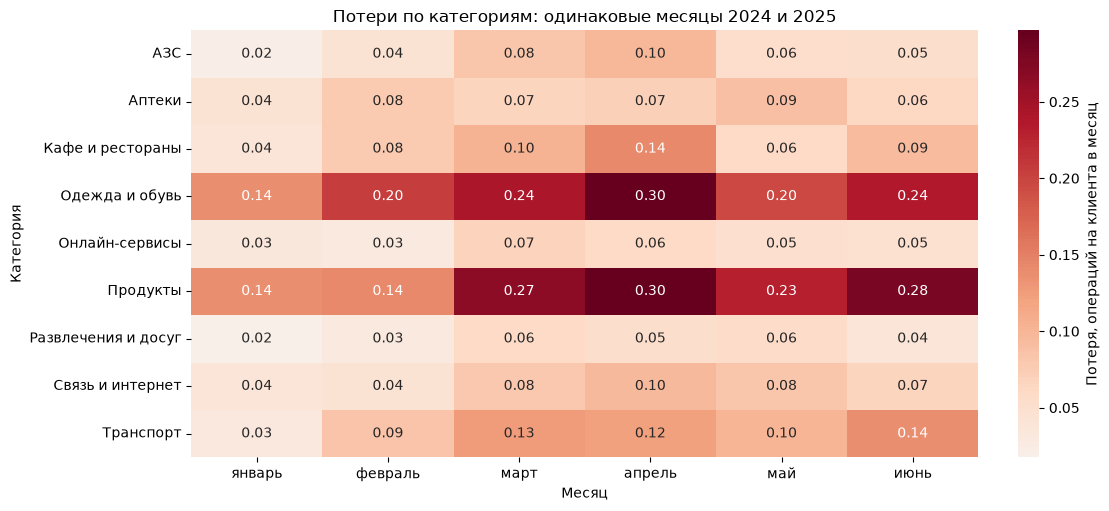

In [82]:
category_monthly = pd.crosstab(full_success['month'], full_success['category']).reindex(months, fill_value=0)
base_categories = category_monthly.loc['2024-01':'2024-06'].reset_index(drop=True)
recent_categories = category_monthly.loc['2025-01':'2025-06'].reset_index(drop=True)
category_loss = (base_categories - recent_categories) / len(cohort)
category_loss.index = ['январь', 'февраль', 'март', 'апрель', 'май', 'июнь']

fig, ax = plt.subplots(figsize=(11, 5), layout='constrained')
sns.heatmap(category_loss.T, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Потеря, операций на клиента в месяц'}, ax=ax)
ax.set_title('Потери по категориям: одинаковые месяцы 2024 и 2025')
ax.set_xlabel('Месяц')
ax.set_ylabel('Категория')
ax.tick_params(axis='y', rotation=0)
plt.show()


В одинаковых месяцах выделяются потери в одежде и продуктах. Теперь сравним средние месяцы всего 2024 и января–июня 2025: календарный состав базы может менять порядок категорий.


In [83]:
category_change = pd.DataFrame({
    'base': category_monthly.loc['2024-01':'2024-12'].sum() / 12 / len(cohort),
    'recent': category_monthly.loc['2025-01':'2025-06'].sum() / 6 / len(cohort),
})
category_change['activity_loss'] = category_change['base'] - category_change['recent']
display(category_change.sort_values('activity_loss', ascending=False).round(3))


,base,recent,activity_loss
category,,,
Продукты,1.816,1.462,0.354
Одежда и обувь,0.813,0.538,0.276
Кафе и рестораны,0.891,0.741,0.150
Транспорт,0.732,0.587,0.145
Связь и интернет,0.538,0.434,0.104
Аптеки,0.499,0.396,0.103
АЗС,0.634,0.531,0.102
Онлайн-сервисы,0.483,0.395,0.089
Развлечения и досуг,0.520,0.441,0.079


Наибольшие годовые потери дают продукты (0,354) и одежда (0,276 операции на клиента в месяц). Общий спад не ограничен одеждой. Проверим равенство суммы каналов и отдельно суммы категорий общей потере.


In [84]:
assert np.isclose(channel_change['activity_loss'].sum(), overall_loss)
assert np.isclose(category_change['activity_loss'].sum(), overall_loss)


**Клиентские признаки и индивидуальная потеря.** `n` — размер группы, `base` и `recent` — средние месячные частоты, `median_loss` — медиана индивидуальной потери. Пропуски сохраняем отдельной строкой. Исходная частота даёт контекст абсолютной потере; медиана индивидуальных разниц может отличаться от разницы средних.

Возрастные интервалы используются для обзора; они не задают пороги поведения. Флаг верхней границы возраста сохраняется.


In [85]:
cohort['age_group'] = pd.cut(cohort['age'], bins=[0, 35, 50, 65, np.inf], right=False,
                            labels=['до 35', '35–49', '50–64', '65 и старше'])
client_stats = {}
for column in ['segment', 'loyalty_tier', 'card_type', 'has_mobile_app', 'age_group', 'city']:
    stats = cohort.groupby(column, observed=True, dropna=False).agg(
        n=('base', 'size'), base=('base', 'mean'), recent=('recent', 'mean'),
        median_loss=('activity_loss', 'median'))
    client_stats[column] = stats
    print(f'{column}: n = {len(cohort)} клиентов')
    display(stats.round(2))

segment_stats = client_stats['segment']
loyalty_stats = client_stats['loyalty_tier']
card_stats = client_stats['card_type']
app_stats = client_stats['has_mobile_app']
age_stats = client_stats['age_group']
city_overview = client_stats['city']


segment: n = 4874 клиентов


,n,base,recent,median_loss
segment,,,,
Private,196,8.89,7.47,1.38
Зарплатный,1372,7.66,7.02,0.67
Массовый,2503,5.96,3.96,1.67
Премиальный,794,8.25,7.41,0.83
<NA>,9,5.84,4.00,1.08


loyalty_tier: n = 4874 клиентов


,n,base,recent,median_loss
loyalty_tier,,,,
Базовый,2520,6.44,4.80,1.42
Золото,852,7.76,6.92,0.92
Платина,248,8.14,6.75,1.17
Серебро,1254,7.10,5.79,1.08


card_type: n = 4874 клиентов


,n,base,recent,median_loss
card_type,,,,
Дебетовая,3374,6.72,5.25,1.25
Кредитная,1071,7.00,5.68,1.25
Премиальная,429,8.37,7.29,1.00


... (2 outputs left out)

age_group: n = 4874 клиентов


,n,base,recent,median_loss
age_group,,,,
до 35,341,8.29,6.94,1.25
35–49,1844,7.63,6.38,1.17
50–64,1681,6.77,5.18,1.33
65 и старше,1008,5.44,4.06,1.17


city: n = 4874 клиентов


,n,base,recent,median_loss
city,,,,
Екатеринбург,592,6.72,5.62,1.00
Казань,844,6.25,4.42,1.50
Москва,1410,7.13,5.81,1.17
Нижний Новгород,602,7.01,5.51,1.29
Новосибирск,612,7.06,5.85,1.17
Санкт-Петербург,804,7.29,5.89,1.25
NaN,10,5.72,5.63,0.62


Массовый сегмент и отсутствие приложения связаны с большей медианной потерей. При этом возрастные группы не образуют последовательного роста потери с возрастом; у дебетовых и кредитных карт медианы одинаковы. Рост уровня лояльности также не сопровождается строгим уменьшением потери: у Платины она выше, чем у Золота.

Одного признака недостаточно для объяснения различий. Проверим сочетание сегмента с приложением и состав городов, учитывая показанные в таблицах исходные частоты.

**Пересечение сегмента и приложения.**

На тепловой карте число и цвет показывают медиану индивидуальной потери операций в месяц внутри сочетания признаков. Более тёмная ячейка означает большую потерю. Размеры групп приведены отдельно. Клиентов с неизвестным сегментом в матрице нет; их число выведем рядом.


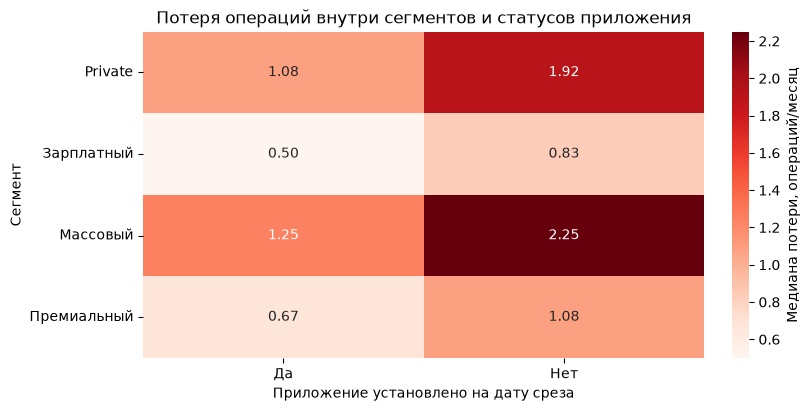

Не показано клиентов с неизвестным сегментом: 9


has_mobile_app,Да,Нет
segment,,
Private,125,71
Зарплатный,854,518
Массовый,1479,1024
Премиальный,496,298


In [86]:
effect = cohort.pivot_table(index='segment', columns='has_mobile_app', values='activity_loss', aggfunc='median')
sizes = pd.crosstab(cohort['segment'], cohort['has_mobile_app'])

fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
sns.heatmap(effect, annot=True, fmt='.2f', cmap='Reds',
            cbar_kws={'label': 'Медиана потери, операций/месяц'}, ax=ax)
ax.set_title('Потеря операций внутри сегментов и статусов приложения')
ax.set_xlabel('Приложение установлено на дату среза')
ax.set_ylabel('Сегмент')
ax.tick_params(axis='y', rotation=0)
plt.show()
print('Не показано клиентов с неизвестным сегментом:', cohort['segment'].isna().sum())

sizes


Внутри каждого сегмента медианная потеря выше у клиентов без приложения; наиболее высокая — у массового сегмента. Это различие не сводится к составу сегментов. Статус приложения на дату среза показывает связь, но не причинный эффект установки.

**Город и состав сегментов.** Для Казани и остальных городов сравним долю массового сегмента и потерю внутри него. Долю считаем среди известных сегментов, `n` показывает всех клиентов города.


In [87]:
city_stats = city_overview.copy()
city_stats['known_segment'] = cohort.groupby('city', dropna=False)['segment'].count()
city_stats['mass_share'] = (cohort['segment'] == 'Массовый').groupby(cohort['city'], dropna=False).mean() * 100
city_stats['mass_median_loss'] = cohort.loc[cohort['segment'] == 'Массовый'].groupby('city', dropna=False)['activity_loss'].median()
city_stats.round(2)

print('Численность и медиана потери массового сегмента по городам:')
display(cohort.loc[cohort['segment'].eq('Массовый')].groupby('city')['activity_loss'].agg(['size', 'median']).round(2))


Численность и медиана потери массового сегмента по городам:


,size,median
city,,
Екатеринбург,278,1.25
Казань,739,1.67
Москва,606,1.92
Нижний Новгород,259,1.67
Новосибирск,273,1.75
Санкт-Петербург,345,1.83


В Казани массовый сегмент занимает большую долю, чем в Москве. Внутри массового сегмента медианная потеря Казани не выше московской. Общий городской разрыв может отражать состав клиентов.

**Доход и потеря активности.** Разделим клиентов по Q1, медиане и Q3 из 5.1. Границы рассчитаны по всем известным доходам справочника и фиксированы для следующих проверок. Пропуск — отдельная строка.


In [88]:
income_edges = [0, income_q1, clients['monthly_income'].median(), income_q3, np.inf]
income_labels = ['до Q1', 'Q1–медиана', 'медиана–Q3', 'выше Q3']
cohort['income_group'] = pd.cut(cohort['monthly_income'], bins=income_edges, labels=income_labels)
income_stats = cohort.groupby('income_group', observed=True, dropna=False).agg(
    n=('base', 'size'), base=('base', 'mean'), recent=('recent', 'mean'),
    median_loss=('activity_loss', 'median'))
income_stats.round(2)


,n,base,recent,median_loss
income_group,,,,
до Q1,1100,6.45,4.70,1.54
Q1–медиана,1112,6.54,5.06,1.29
медиана–Q3,1103,6.82,5.60,1.08
выше Q3,1049,7.85,6.83,1.00
NaN,510,7.13,5.47,1.17


С ростом доходной группы медианная потеря уменьшается, хотя исходная частота выше. Сначала посмотрим форму связи внутри каждого сегмента: нет ли изгиба, отдельных скоплений или точек, которые могут влиять на общий коэффициент. Шкалы одинаковы во всех панелях; логарифмическая ось дохода помогает показать широкий диапазон значений.


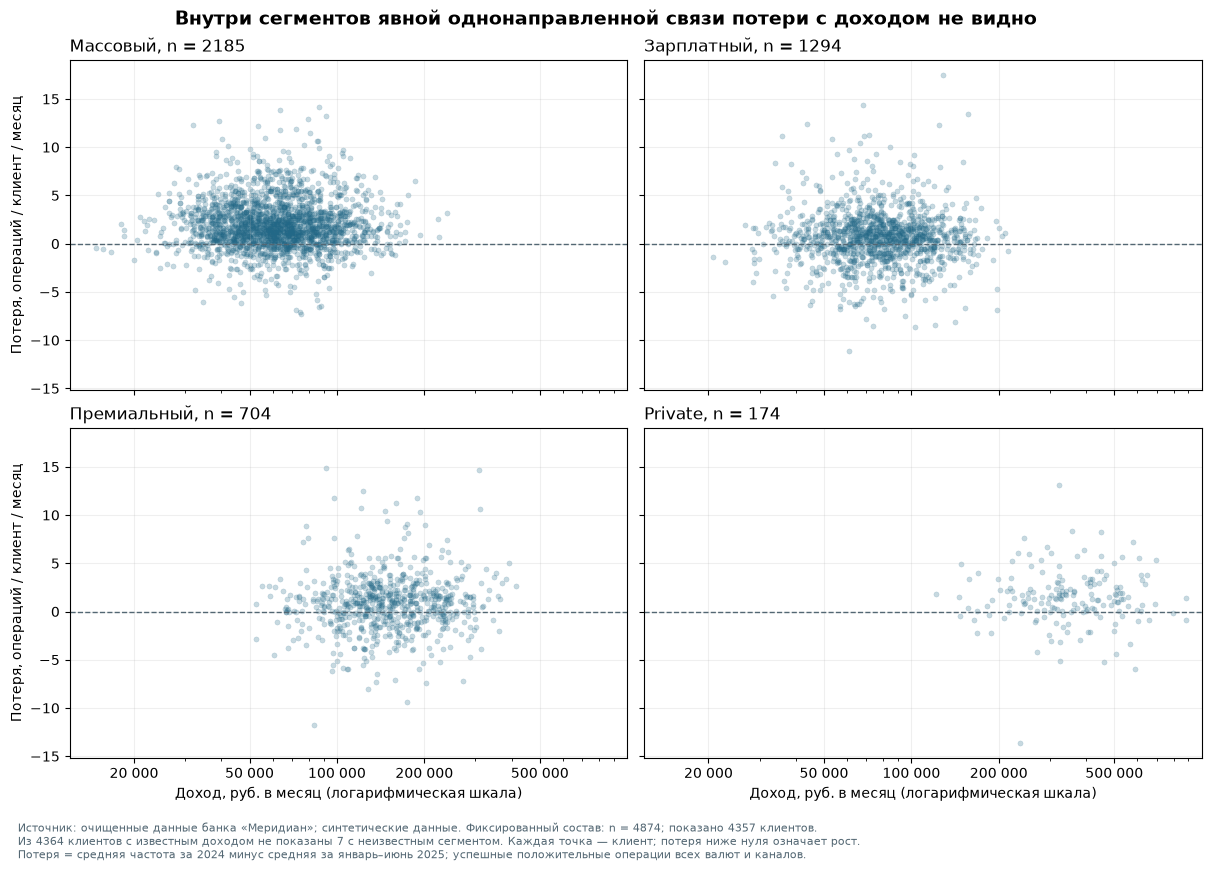

In [89]:
income_sample = cohort.loc[cohort['monthly_income'].notna()]
income_plot_sample = income_sample.dropna(subset=['segment'])
income_segment_order = ['Массовый', 'Зарплатный', 'Премиальный', 'Private']

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True,
                         layout='constrained')
for ax, segment in zip(axes.flat, income_segment_order):
    part = income_plot_sample.loc[income_plot_sample['segment'] == segment]
    sns.scatterplot(data=part, x='monthly_income', y='activity_loss',
                    color='#226887', alpha=.25, s=14, edgecolor=None, ax=ax)
    ax.set_xscale('log')
    ax.tick_params(axis='x', which='minor', labelbottom=False)
    ax.axhline(0, color='#536773', linestyle='--', linewidth=1)
    ax.set_title(f'{segment}, n = {len(part)}', loc='left')
    ax.set_xlabel('Доход, руб. в месяц (логарифмическая шкала)')
    ax.set_ylabel('Потеря, операций / клиент / месяц')
    ax.grid(alpha=.2)
axes[0, 0].set_xlim(12000, 1000000)
axes[0, 0].set_xticks([20000, 50000, 100000, 200000, 500000],
                     ['20 000', '50 000', '100 000', '200 000', '500 000'])
fig.suptitle('Внутри сегментов явной однонаправленной связи потери с доходом не видно',
             fontsize=14, fontweight='bold')
fig.text(.01, -.02,
    f'Источник: очищенные данные банка «Меридиан»; синтетические данные. '
    f'Фиксированный состав: n = {len(cohort)}; показано {len(income_plot_sample)} клиентов.\n'
    f'Из {len(income_sample)} клиентов с известным доходом не показаны '
    f'{len(income_sample) - len(income_plot_sample)} с неизвестным сегментом. '
    'Каждая точка — клиент; потеря ниже нуля означает рост.\n'
    'Потеря = средняя частота за 2024 минус средняя за январь–июнь 2025; '
    'успешные положительные операции всех валют и каналов.',
    fontsize=8, color='#536773', va='top', ha='left')
plt.show()


На 4357 клиентах с известными доходом и сегментом видны разные диапазоны доходов и большой разброс потери внутри каждого сегмента. Явного монотонного тренда или изгиба внутри сегментов визуально не видно. Семь клиентов с неизвестным сегментом не показаны; в общем коэффициенте они учитываются.

Теперь рассчитаем ранговую корреляцию на всех 4364 клиентах с известным доходом, затем проверим состав доходных групп. Коэффициент от −1 до 1 показывает направленность монотонной связи: отрицательный — большему доходу соответствует меньшая потеря, около нуля — выраженной монотонной связи нет.


In [90]:
income_corr = income_sample['monthly_income'].rank().corr(income_sample['activity_loss'].rank())
print('Клиентов с известным доходом:', len(income_sample))
print('Ранговая корреляция дохода и потери:', round(income_corr, 3))


Клиентов с известным доходом: 4364
Ранговая корреляция дохода и потери: -0.1


Общая ранговая корреляция −0,100 на 4364 клиентах с доходом. Это слабая связь; коэффициент не является процентом потери операций. Проверим состав доходных групп: в каждой строке тепловой карты доли сегментов суммируются до 100%. Доход и сегмент должны быть известны.


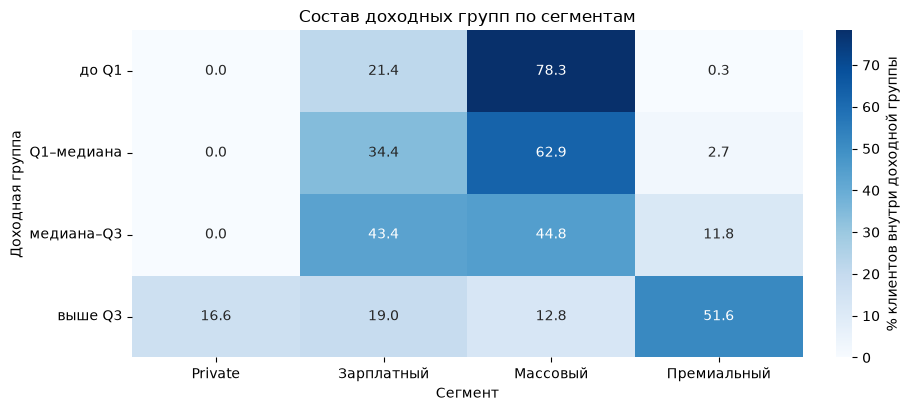

Показано клиентов с известными доходом и сегментом: 4357


In [91]:
income_segment_sample = cohort.dropna(subset=['income_group', 'segment'])
income_segment_share = pd.crosstab(income_segment_sample['income_group'],
                                 income_segment_sample['segment'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
sns.heatmap(income_segment_share, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': '% клиентов внутри доходной группы'}, ax=ax)
ax.set_title('Состав доходных групп по сегментам')
ax.set_xlabel('Сегмент')
ax.set_ylabel('Доходная группа')
ax.tick_params(axis='y', rotation=0)
plt.show()
print('Показано клиентов с известными доходом и сегментом:', len(income_segment_sample))


В группе «до Q1» преобладает массовый сегмент; в группе «выше Q3» — премиальный, также выше доля Private. Сегменты различаются по потере, поэтому состав может влиять на общую связь дохода с потерей. Проверим коэффициенты внутри сегментов и общий коэффициент на том же составе клиентов.


In [92]:
income_corr_known_segment = income_segment_sample['monthly_income'].rank().corr(income_segment_sample['activity_loss'].rank())
print('Общая ранговая корреляция на тех же клиентах:', round(income_corr_known_segment, 3))

income_correlations = []
for segment, part in income_segment_sample.groupby('segment'):
    correlation = part['monthly_income'].rank().corr(part['activity_loss'].rank())
    income_correlations.append({'сегмент': segment, 'клиентов': len(part), 'ранговая корреляция': correlation})
pd.DataFrame(income_correlations).round(3)


Общая ранговая корреляция на тех же клиентах: -0.1


,сегмент,клиентов,ранговая корреляция
0,Private,174,0.010
1,Зарплатный,1294,-0.011
2,Массовый,2185,-0.023
3,Премиальный,704,0.048


Внутри сегментов ранговые коэффициенты близки к нулю и имеют разные знаки. Общая слабая отрицательная связь не повторяется в каждом сегменте, что согласуется с ролью состава доходных групп.

Проверим порядок групповых медиан без `income_scaled=True`, сохранив границы доходных групп и отдельную строку пропусков.


In [93]:
income_without_scaled = cohort.loc[~cohort['income_scaled']]
income_sensitivity = income_without_scaled.groupby('income_group', observed=True, dropna=False).agg(
    n=('base', 'size'), base=('base', 'mean'), recent=('recent', 'mean'),
    median_loss=('activity_loss', 'median'))
print('Исключено клиентов с доходом, умноженным на 1000:', cohort['income_scaled'].sum())
income_sensitivity.round(2)


Исключено клиентов с доходом, умноженным на 1000: 136


,n,base,recent,median_loss
income_group,,,,
до Q1,1066,6.45,4.68,1.58
Q1–медиана,1078,6.52,5.04,1.25
медиана–Q3,1072,6.83,5.62,1.08
выше Q3,1012,7.86,6.84,1.00
NaN,510,7.13,5.47,1.17


Без пересчитанных доходов медианная потеря по-прежнему уменьшается от «до Q1» к «выше Q3». Это проверка устойчивости порядка групп, а не подтверждение единиц дохода.

**Давность входа в приложение.** Рассмотрим клиентов с приложением и известным месяцем входа. На графике одна точка — клиент: горизонталь показывает месяцы до среза, вертикаль — потерю к 2024. Если более давний вход связан с большей потерей, справа точки должны располагаться выше. Полосы возникают из-за месячной точности входа; ноль означает июнь 2025. Посчитаем ранговую корреляцию.


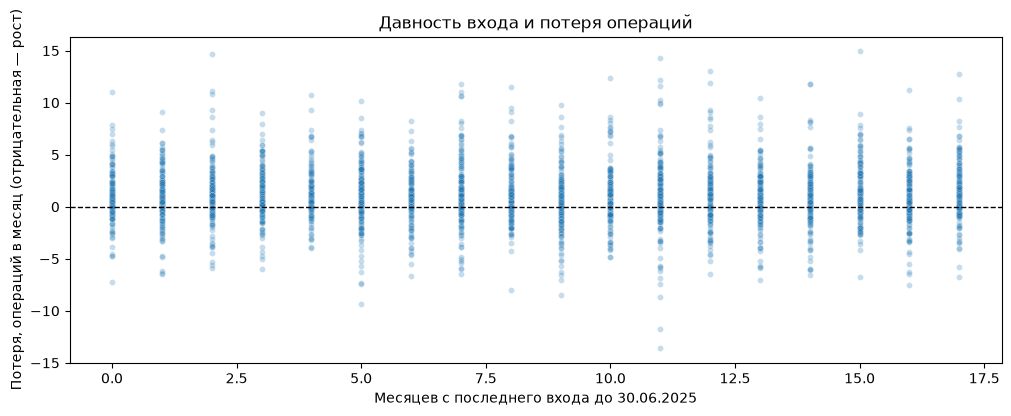

Клиентов в проверке: 2960
Ранговая корреляция давности входа и потери: 0.006


In [94]:
login_sample = cohort.loc[(cohort['has_mobile_app'] == 'Да') & cohort['app_last_login'].notna()].copy()
login_sample['months_since_login'] = ((SNAPSHOT.year - login_sample['app_last_login'].dt.year) * 12
                                    + SNAPSHOT.month - login_sample['app_last_login'].dt.month)
login_corr = login_sample['months_since_login'].rank().corr(login_sample['activity_loss'].rank())

fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
sns.scatterplot(data=login_sample, x='months_since_login', y='activity_loss', alpha=0.25, s=18, ax=ax)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('Давность входа и потеря операций')
ax.set_xlabel('Месяцев с последнего входа до 30.06.2025')
ax.set_ylabel('Потеря, операций в месяц (отрицательная — рост)')
plt.show()
print('Клиентов в проверке:', len(login_sample))
print('Ранговая корреляция давности входа и потери:', round(login_corr, 3))


При разной давности входа есть и потеря, и рост частоты. Ранговая корреляция близка к нулю; направленной связи «чем дольше не входил, тем больше потеря» в этой группе не видно. Истории использования приложения нет, поэтому результат не объясняет причины поведения.


In [95]:
add_log('age_group, income_group', 'Добавлены обзорные клиентские группы',
        'Основная когорта индивидуальных изменений', len(cohort),
        'Возраст и доход после пересчёта единиц', 'добавлено', 'Возрастные интервалы и группы по фиксированным квартильным границам',
        'Описать связи; эти интервалы сами по себе не задают правила кампании')


**Выводы по разведочному анализу.** Частота операций уменьшается и относительно всего 2024 года, и относительно одинаковых месяцев. Потери «Карты» частично компенсируются ростом «Токена». Провал «Онлайн-банка» в марте–апреле заметно ослабевает к маю–июню. В годовом сравнении наибольший абсолютный вклад среди категорий дают продукты и одежда.

Дополнительные проверки показывают, что среднемесячная доля активных и частота среди активных снизились. У части тех же клиентов сокращение «Карты» сочетается с ростом «Токена», но общей потери это часто не устраняет. Провал онлайн-банка не сопровождается ростом доли зарегистрированных отказов; его причина остаётся неизвестной.

В клиентских разрезах выделяется массовый сегмент, особенно клиенты без приложения. При этом возрастные группы не дают простого последовательного роста потери с возрастом, а дебетовые и кредитные карты имеют одинаковую медиану. Городские и доходные различия требуют учёта состава сегментов. У давности входа не обнаружена заметная направленная связь с потерей. Эти результаты задают направления поиска групп; правила кампании пока не определены.

## 6. Метрика активности

### 6.1. Определение и выбор показателя

Для дальнейшего поиска и отбора групп выбираем среднее число уникальных успешных операций с положительной суммой за календарный месяц. Его изменение измеряем абсолютной разницей частот между базовым и оцениваемым периодами. При выборе учитываем результаты разведочного анализа раздела 5. Единица анализа — клиент. Учитываем все четыре канала и все валюты, поскольку число операций не требует валютного пересчёта. Отказы и возвраты не добавляют успешную операцию в счётчик.

Заказчик рассматривает сокращение частоты использования. Поэтому изменение измеряем в операциях в месяц: показатель имеет понятные единицы и позволяет разложить общую потерю по каналам или категориям. Сумма разниц по каналам или категориям, где рост учитывается со знаком минус, равна общей потере.

### 6.2. Окна и формула сравнения

Для клиента $i$ обозначим число операций за 2024 год как $N_{i,2024}$, за январь–июнь 2025 — как $N_{i,2025}$.

$$
\mathrm{base}_i = \frac{N_{i,2024}}{12}, \qquad
\mathrm{recent}_i = \frac{N_{i,2025}}{6}.
$$

В знаменатель входят все месяцы окна, включая месяцы без операций. Например, 120 операций за год и 60 за полугодие дают одинаковую частоту — 10 операций в месяц.

$$
\mathrm{activity\_loss}_i = \mathrm{base}_i - \mathrm{recent}_i.
$$

Положительная разница означает снижение, нулевая — прежнюю частоту, отрицательная — рост. Значение 2 означает потерю двух операций в месяц. При нулевой базе показатель также определён: появление операций даёт отрицательную разницу, отсутствие операций в обоих окнах — ноль.

Средняя потеря по группе показывает изменение общего числа операций в расчёте на клиента. Медиана индивидуальных потерь описывает типичного клиента группы. Эти величины могут различаться.

### 6.3. Состав сравнения

Общие временные ряды и клиентские разрезы относятся к фиксированному составу: клиентам с регистрацией и открытием текущей карты не позже 01.01.2024. Клиенты с нулевыми или редкими операциями включены. Клиенты с более поздней регистрацией или картой остаются в справочнике, но не участвуют в сравнении полных окон.

Признак `full_history` обозначает выполнение обоих условий доступности базового окна. Начало наблюдаемой истории проверено по первой операции; внутреннюю полноту выгрузки подтвердить нельзя. Пропуски дохода, оценки и других клиентских признаков не препятствуют расчёту частоты. Согласие на маркетинг применяется при формировании кампании, а не при описании всей базы.

### 6.4. Календарные различия и характер падения

Основная база — весь 2024 год, оцениваемый период — январь–июнь 2025. В разделе 5.3 дополнительно сопоставлены одинаковые полугодия: календарный состав окон влияет на размер потери и иногда на направление индивидуального изменения.

Для описания групп используем также помесячные ряды. Они позволяют отличать временный провал, восстановление и продолжающееся сокращение. Само условие `activity_loss > 0` задаёт факт снижения частоты, но не содержательную группу кампании и не доказательство ухода клиента.

### 6.5. Ограничения метрики

- При одинаковом относительном снижении абсолютная потеря больше у изначально активных клиентов. Потеря двух операций может означать небольшое изменение для частого пользователя и почти полное прекращение для редкого. Поэтому в клиентских таблицах показаны также исходные частоты.
- Одинаково учитываются малые и крупные операции. Сокращение денежных сумм при прежнем количестве операций метрика не выявляет.
- Падение одного канала может компенсироваться другим. Тогда общая частота не уменьшается, хотя способ использования изменился.
- Потеря к концу периода может сгладиться в среднем за полугодие; для этого нужна месячная динамика.
- Успешная операция с последующим возвратом остаётся учтённой: связи возврата с исходной операцией в данных нет.
- Переход в другой банк и причины поведения напрямую не наблюдаются. Выводы относятся к выданной выгрузке и клиентам справочника на дату среза.

## 7. Поиск и описание групп

В разделе 5 выделились сокращение операций в категории «Одежда и обувь», снижение у массовых клиентов без приложения и потери канала «Карта». Проверим эти направления на уровне клиентов. Для кампании нужны не только положительные потери за полугодие, но и понятный характер изменения, сохраняющийся к концу периода.

### 7.1. От общего снижения к кандидатам

Используем метрику раздела 6. Сначала оставим клиентов с доступным базовым окном по обеим датам и согласием на маркетинг. Для отбора зададим рабочий порог: потеря хотя бы одной операции в месяц. Это соответствует как минимум шести недостающим операциям за январь–июнь относительно среднего темпа 2024 года. Порог ограничивает малые изменения, но не доказывает статистическую значимость и сам по себе не определяет группу. Ниже проверим результат при соседних порогах.

Среднее за полугодие может скрывать восстановление. Поэтому отдельно сравним каждый квартал 2025 года с тем же кварталом 2024 и проверим май–июнь. К концу периода частота должна оставаться ниже и тех же месяцев прошлого года, и среднего за весь базовый год.


In [96]:
group_data = cohort.copy()
group_monthly = monthly.loc[group_data.index]

group_data['q1_loss'] = (group_monthly.loc[:, '2024-01':'2024-03'].mean(axis=1)
                         - group_monthly.loc[:, '2025-01':'2025-03'].mean(axis=1))
group_data['q2_loss'] = (group_monthly.loc[:, '2024-04':'2024-06'].mean(axis=1)
                         - group_monthly.loc[:, '2025-04':'2025-06'].mean(axis=1))
group_data['late_2024'] = group_monthly.loc[:, '2024-05':'2024-06'].mean(axis=1)
group_data['late_2025'] = group_monthly.loc[:, '2025-05':'2025-06'].mean(axis=1)

consenting = group_data['marketing_opt_in'] == 'Да'
# Округление не даёт потерять ровно 1 операцию из-за погрешности вычислений.
noticeable_loss = group_data['activity_loss'].round(6) >= 1
same_quarters = (group_data['q1_loss'] > 0) & (group_data['q2_loss'] > 0)
late_lower = ((group_data['late_2025'] < group_data['late_2024'])
              & (group_data['late_2025'] < group_data['base']))
stable_change = consenting & same_quarters & late_lower
stable_candidates = stable_change & noticeable_loss

selection_steps = pd.DataFrame({
    'условие, применяемое последовательно': [
        'Регистрация и текущая карта не позже 01.01.2024',
        'Есть согласие на маркетинг',
        'Частота за полугодие снизилась',
        'Потеря не меньше 1 операции в месяц',
        'Оба квартала ниже тех же кварталов 2024',
        'Май–июнь ниже тех же месяцев 2024 и годовой базы',
    ],
    'клиентов': [
        len(group_data),
        consenting.sum(),
        (consenting & (group_data['activity_loss'] > 0)).sum(),
        (consenting & noticeable_loss).sum(),
        (consenting & noticeable_loss & same_quarters).sum(),
        stable_candidates.sum(),
    ],
})
display(selection_steps)


,"условие, применяемое последовательно",клиентов
0,Регистрация и текущая карта не позже 01.01.2024,4874
1,Есть согласие на маркетинг,4296
2,Частота за полугодие снизилась,3127
3,Потеря не меньше 1 операции в месяц,2379
4,Оба квартала ниже тех же кварталов 2024,1797
5,Май–июнь ниже тех же месяцев 2024 и годовой базы,1600


Снижение среднего за полугодие не всегда сопровождается снижением в обоих кварталах и сохранением потери в мае–июне. Для 1600 клиентов выполнены все условия. Это ещё не список кампании: далее нужно установить, что именно у них изменилось.

### 7.2. Какие операции дают потерю

Разложим годовую потерю каждого клиента по каналам и категориям. Число операций 2024 года делим на 12, первого полугодия 2025 — на 6; месяцы без операций входят в знаменатели. Положительный вклад означает сокращение, отрицательный — рост.

Внутри каждого разреза вклады складываются в общую потерю. Каналы и категории описывают одни и те же операции с разных сторон, поэтому их вклады между собой не складываем.


In [97]:
success_2024 = success.loc[success['txn_datetime'] < '2025-01-01']
success_2025 = success.loc[success['txn_datetime'] >= '2025-01-01']

client_channel_base = (success_2024.groupby(['client_id', 'channel']).size()
                       .unstack(fill_value=0).reindex(group_data.index, fill_value=0) / 12)
client_channel_recent = (success_2025.groupby(['client_id', 'channel']).size()
                         .unstack(fill_value=0).reindex(group_data.index, fill_value=0) / 6)
client_channel_loss = (client_channel_base - client_channel_recent).round(6)
channel_candidates = client_channel_loss.loc[stable_candidates]

pd.DataFrame({
    'средняя потеря, операций на клиента в месяц': channel_candidates.mean(),
    'доля операций 2024, %': 100 * client_channel_base.loc[stable_candidates].sum() / group_data.loc[stable_candidates, 'base'].sum(),
    'доля совокупной потери, %': 100 * channel_candidates.sum() / group_data.loc[stable_candidates, 'activity_loss'].sum(),
    'клиентов с наибольшим вкладом канала': channel_candidates.eq(
        channel_candidates.max(axis=1), axis=0).sum(),
}).sort_values('средняя потеря, операций на клиента в месяц', ascending=False)


,"средняя потеря, операций на клиента в месяц","доля операций 2024, %","доля совокупной потери, %",клиентов с наибольшим вкладом канала
channel,,,,
Карта,2.063229,51.723228,54.176696,1174
Онлайн-банк,0.675156,16.017218,17.728392,126
СБП,0.659583,17.700114,17.319475,160
Токен,0.410365,14.559440,10.775437,175


«Карта» даёт наибольшую среднюю потерю, но она же крупнейший канал в базе. Большой абсолютный вклад может отражать размер канала и не выделяет отдельную причину. Поэтому «кто» зададим независимо: более половины успешных операций 2024 проходило через пластиковую карту. К этому признаку добавим характер снижения общей частоты и ведущий вклад «Карты» в потерю.


In [98]:
client_category_base = (success_2024.groupby(['client_id', 'category']).size()
                        .unstack(fill_value=0).reindex(group_data.index, fill_value=0) / 12)
client_category_recent = (success_2025.groupby(['client_id', 'category']).size()
                          .unstack(fill_value=0).reindex(group_data.index, fill_value=0) / 6)
client_category_loss = (client_category_base - client_category_recent).round(6)
category_candidates = client_category_loss.loc[stable_candidates]

pd.DataFrame({
    'средняя потеря, операций на клиента в месяц': category_candidates.mean(),
    'клиентов с наибольшим вкладом категории': category_candidates.eq(
        category_candidates.max(axis=1), axis=0).sum(),
}).sort_values('средняя потеря, операций на клиента в месяц', ascending=False)


,"средняя потеря, операций на клиента в месяц",клиентов с наибольшим вкладом категории
category,,
Продукты,1.024219,997
Одежда и обувь,0.563281,271
Кафе и рестораны,0.427135,127
Транспорт,0.404583,117
АЗС,0.309792,56
Связь и интернет,0.296979,45
Аптеки,0.290260,50
Онлайн-сервисы,0.246458,30
Развлечения и досуг,0.245625,31


Продукты дают крупный вклад, но это частая категория повседневных покупок. Для сценария одежды зададим независимую характеристику трат: покупки в этой категории были хотя бы в шести из двенадцати месяцев 2024. Это рабочее определение регулярности — присутствие в половине месяцев базы. Оно не основано на величине падения. Затем потребуем, чтобы одежда давала наибольшую потерю среди категорий. Равные максимумы допускаются.

Третье направление — массовые клиенты без приложения. Здесь проверим, распространяется ли снижение на разные операции. Статус приложения известен на дату среза.

### 7.3. Правила и пересечения

У всех групп одинаковые условия доступности периода, согласия и сохраняющегося снижения из 7.1. Характеристика «кто» считается отдельно от падения:

| Группа | Кто это | Что произошло |
|---|---|---|
| Одежда и обувь | Покупали одежду хотя бы в 6 месяцах 2024 года | Общая потеря ≥1 операции в месяц; оба квартала и май–июнь ниже сопоставимой базы; одежда даёт наибольшую потерю среди категорий |
| Массовый без приложения | Массовый сегмент, приложение не установлено на дату среза | Те же условия общей потери, кварталов и мая–июня; далее описываем её распространённость по каналам и категориям |
| Карта | Более 50% успешных операций 2024 проходило через пластиковую карту | Те же условия общей потери, кварталов и мая–июня; «Карта» даёт наибольшую потерю среди каналов |

Правила определяют аудиторию и тему общения. Ведущий вклад в потерю не устанавливает причину изменения поведения.


In [99]:
# Признаки «кто» считаются по базовому 2024 году, отдельно от падения.
group_data['clothes_months_2024'] = (success_2024.loc[success_2024['category'].eq('Одежда и обувь')]
    .groupby('client_id')['month'].nunique().reindex(group_data.index, fill_value=0))
group_data['card_share_2024'] = client_channel_base['Карта'] / group_data['base'].replace(0, np.nan)

group_flags = pd.DataFrame(index=group_data.index)
group_flags['Одежда и обувь'] = (
    group_data['clothes_months_2024'].ge(6)
    & client_category_loss['Одежда и обувь'].eq(client_category_loss.max(axis=1)))
group_flags['Массовый без приложения'] = (
    (group_data['segment'] == 'Массовый') & (group_data['has_mobile_app'] == 'Нет')
).fillna(False)
group_flags['Карта'] = (
    group_data['card_share_2024'].gt(.5)
    & client_channel_loss['Карта'].eq(client_channel_loss.max(axis=1)))

rules = group_flags.copy()
for name in rules:
    rules[name] = rules[name] & stable_candidates

display(rules.sum().rename('кандидатов до разрешения пересечений'))
overlaps = pd.DataFrame({
    'пересечение': ['Одежда и массовый без приложения',
                   'Одежда и Карта', 'Массовый без приложения и Карта'],
    'клиентов': [
        (rules['Одежда и обувь'] & rules['Массовый без приложения']).sum(),
        (rules['Одежда и обувь'] & rules['Карта']).sum(),
        (rules['Массовый без приложения'] & rules['Карта']).sum(),
    ],
})
print('Подходят сразу под несколько правил:', (rules.sum(axis=1) > 1).sum())
display(overlaps)
add_log('clothes_months_2024, card_share_2024', 'Базовые признаки трат для содержательных групп',
        'Клиенты с полным базовым окном', len(group_data), 'Счётчики успешных положительных операций 2024',
        'добавлено', 'Число месяцев с одеждой; доля пластикового канала в базовых операциях',
        'Отделить характеристику клиента и его трат от наблюдаемого снижения')


Одежда и обувь              242
Массовый без приложения     550
Карта                      1086
Name: кандидатов до разрешения пересечений, dtype: Int64

Подходят сразу под несколько правил: 592


,пересечение,клиентов
0,Одежда и массовый без приложения,37
1,Одежда и Карта,154
2,Массовый без приложения и Карта,455


**Решение.** В исследовании пересечения сохраняем: сокращение покупок одежды может одновременно происходить у массового клиента без приложения и затрагивать оплату картой. Для итогового списка задаём приоритет сценариев общения. Сначала выделяем конкретную категорию покупок — одежду. Затем среди остальных выделяем массовых клиентов без приложения: для них отдельно имеет смысл выяснять удобство доступных способов обслуживания. Канальный сценарий «Карта» применяем к оставшимся.

Так один клиент получает одну тему обращения. Приоритет не означает, что остальные признаки или составляющие потери исчезли. Порядок фиксирован и применяется к новой выгрузке по тем же правилам.


In [100]:
assigned_group = pd.Series(index=group_data.index, dtype='string')
for name in rules:
    assigned_group.loc[rules[name] & assigned_group.isna()] = name

group_data['group'] = assigned_group
campaign = group_data.loc[group_data['group'].notna()].reset_index()
group_order = list(rules.columns)
group_sizes = campaign['group'].value_counts().reindex(group_order)

pd.DataFrame({
    'до разрешения пересечений': rules.sum(),
    'в итоговой кампании': group_sizes,
})


,до разрешения пересечений,в итоговой кампании
Одежда и обувь,242,242
Массовый без приложения,550,513
Карта,1086,504


### 7.4. Характер итоговых групп

Далее описываем уже непересекающиеся группы. Средняя частота показывает изменение общего числа операций в расчёте на клиента. Медиана потери характеризует типичного клиента и меньше зависит от отдельных больших изменений. Все частоты и потери ниже измерены в операциях на клиента в месяц.


In [101]:
group_stats = campaign.groupby('group').agg(
    n=('client_id', 'size'),
    base=('base', 'mean'),
    recent=('recent', 'mean'),
    mean_loss=('activity_loss', 'mean'),
    median_loss=('activity_loss', 'median'),
).reindex(group_order)
group_stats.rename(columns={
    'n': 'клиентов', 'base': 'база 2024', 'recent': 'январь–июнь 2025',
    'mean_loss': 'средняя потеря', 'median_loss': 'медиана потери',
}).round(2)


,клиентов,база 2024,январь–июнь 2025,средняя потеря,медиана потери
group,,,,,
Одежда и обувь,242,8.41,5.11,3.30,2.92
Массовый без приложения,513,6.02,2.12,3.90,3.25
Карта,504,7.22,3.30,3.92,3.25


**Распределение индивидуальных потерь.** Проверим, насколько похожи участники внутри каждой итоговой группы по величине снижения. Среднее и медиана не показывают ширину распределения. Коробка охватывает центральные 50% клиентов, линия внутри неё — медиана, ромб — среднее; точки за усами сохраняют крайние наблюдения.


,Q1,Медиана,Q3,МКР
group,,,,
Одежда и обувь,2.00,2.92,3.92,1.92
Массовый без приложения,2.33,3.25,5.00,2.67
Карта,2.25,3.25,5.00,2.75


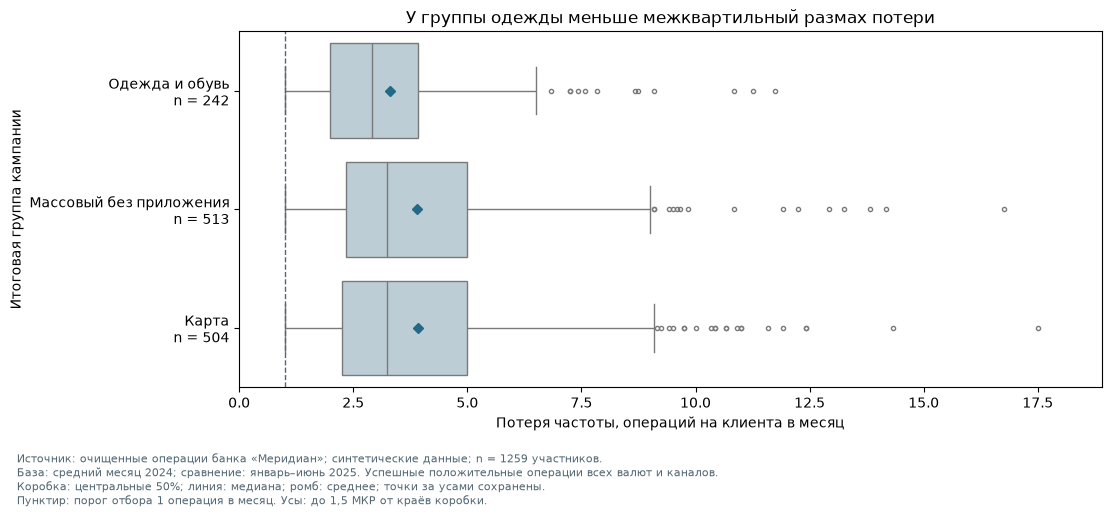

In [102]:
group_loss_quartiles = campaign.groupby('group')['activity_loss'].quantile([0.25, 0.5, 0.75], interpolation='linear').unstack().reindex(group_order)
group_loss_iqr = group_loss_quartiles[0.75] - group_loss_quartiles[0.25]
display(group_loss_quartiles.rename(columns={0.25: 'Q1', 0.5: 'Медиана', 0.75: 'Q3'}).assign(МКР=group_loss_iqr).round(2))

fig, ax = plt.subplots(figsize=(11, 4.3), layout='constrained')
sns.boxplot(data=campaign, x='activity_loss', y='group', order=group_order,
            color='#b9cfd9', showfliers=True, fliersize=3, showmeans=True,
            meanprops={'marker': 'D', 'markerfacecolor': '#226887',
                       'markeredgecolor': '#226887', 'markersize': 5}, ax=ax)
ax.set_yticks(range(len(group_order)), [f'{name}\nn = {group_sizes.loc[name]}' for name in group_order])
ax.axvline(1, color='#536773', linestyle='--', linewidth=1)
ax.set_xlim(0, campaign['activity_loss'].max() * 1.08)
ax.set_title('У группы одежды меньше межквартильный размах потери')
ax.set_xlabel('Потеря частоты, операций на клиента в месяц')
ax.set_ylabel('Итоговая группа кампании')
ax.grid(axis='y', visible=False)
fig.text(.01, -.04,
    f'Источник: очищенные операции банка «Меридиан»; синтетические данные; n = {len(campaign)} участников.\n'
    'База: средний месяц 2024; сравнение: январь–июнь 2025. Успешные положительные операции всех валют и каналов.\n'
    'Коробка: центральные 50%; линия: медиана; ромб: среднее; точки за усами сохранены.\n'
    'Пунктир: порог отбора 1 операция в месяц. Усы: до 1,5 МКР от краёв коробки.',
    fontsize=8, color='#536773', va='top', ha='left')
plt.show()


Межквартильный размах потери у группы одежды — 1,92 операции в месяц, у массовой группы — 2,67, у «Карты» — 2,75. Центральные 50% участников группы одежды ближе друг к другу по величине снижения. Распределения перекрываются; график описывает уже отобранных участников с потерей не ниже одной операции в месяц.

Одинаковая средняя потеря может скрывать разные траектории. Покажем все 18 месяцев на неизменном составе каждой итоговой группы. Пунктир обозначает её среднюю частоту за весь 2024 год. Во всех панелях одна шкала Y с началом в нуле, чтобы сравнивать уровень и величину колебаний.


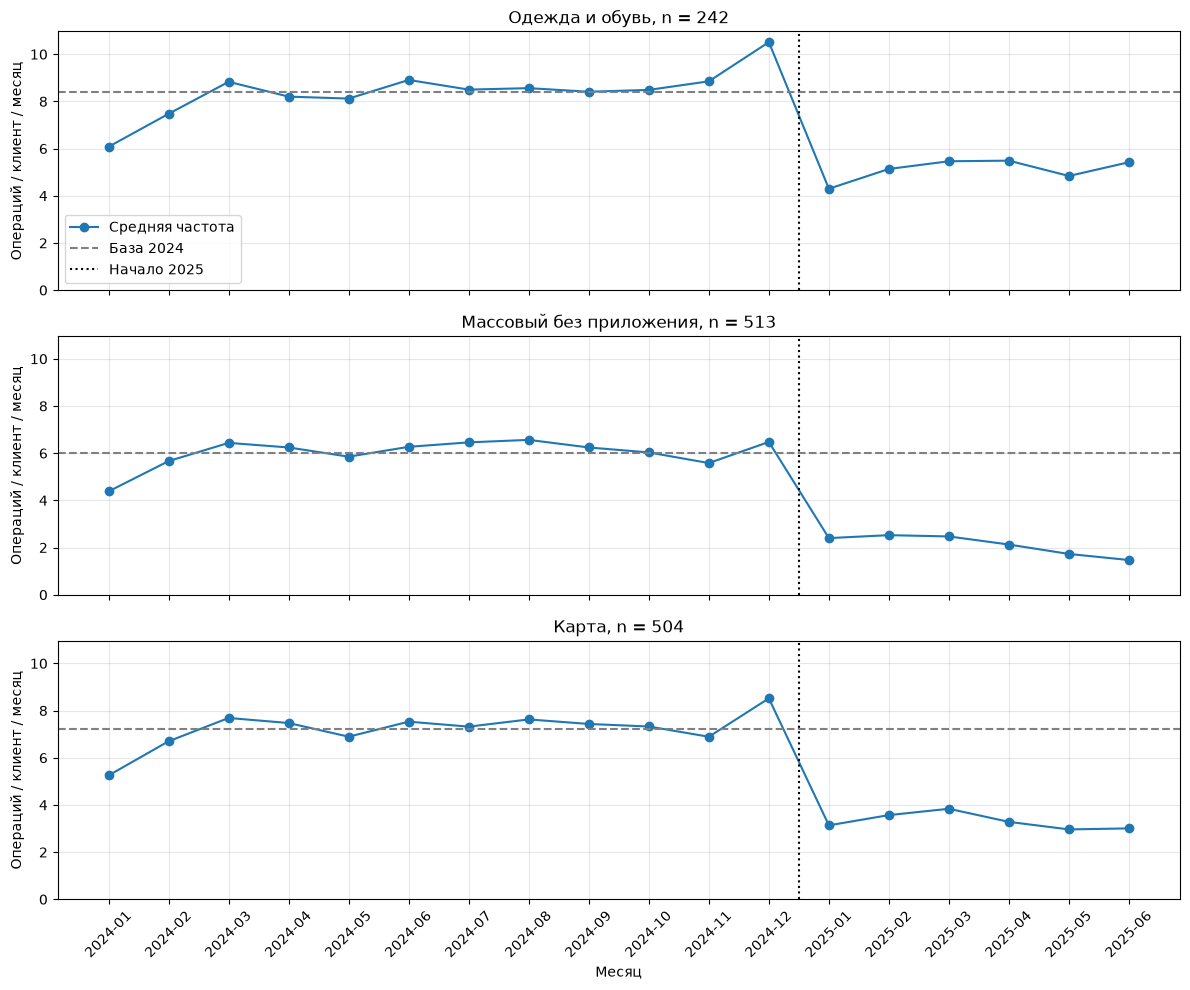

In [103]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)
for ax, name in zip(axes, group_order):
    ids = campaign.loc[campaign['group'] == name, 'client_id']
    values = monthly.loc[ids].mean()
    ax.plot(range(18), values, marker='o', label='Средняя частота')
    ax.axhline(group_stats.loc[name, 'base'], color='gray', linestyle='--', label='База 2024')
    ax.axvline(11.5, color='black', linestyle=':', label='Начало 2025')
    ax.set_title(f'{name}, n = {len(ids)}')
    ax.set_ylabel('Операций / клиент / месяц')
    ax.grid(alpha=0.3)
axes[0].set_ylim(bottom=0)
axes[0].legend()
axes[-1].set_xticks(range(18), monthly.columns, rotation=45)
axes[-1].set_xlabel('Месяц')
plt.tight_layout()
plt.show()


В группе одежды частота в 2025 году держится на более низком уровне, но последовательного помесячного падения нет. У массовых клиентов без приложения средняя активность к концу полугодия продолжает уменьшаться. В группе «Карта» частичное оживление к марту сменяется более низкой активностью в апреле–июне. Следовательно, одинаковый отбор по средней потере не означает одинаковый ход изменения.

Покажем размер потерь относительно тех же кварталов и последних двух месяцев 2024 года. Эти условия уже использовались при отборе: таблица описывает полученные группы, а не служит независимой проверкой.


In [104]:
group_calendar_check = campaign.assign(
    late_season_loss=campaign['late_2024'] - campaign['late_2025'],
    late_base_loss=campaign['base'] - campaign['late_2025'],
).groupby('group')[['q1_loss', 'q2_loss', 'late_season_loss', 'late_base_loss']].mean()
group_calendar_check.reindex(group_order).rename(columns={
    'q1_loss': 'I квартал к I кварталу 2024',
    'q2_loss': 'II квартал ко II кварталу 2024',
    'late_season_loss': 'май–июнь к маю–июню 2024',
    'late_base_loss': 'май–июнь к годовой базе 2024',
}).round(2)


,I квартал к I кварталу 2024,II квартал ко II кварталу 2024,май–июнь к маю–июню 2024,май–июнь к годовой базе 2024
group,,,,
Одежда и обувь,2.50,3.16,3.38,3.28
Массовый без приложения,3.03,4.35,4.46,4.42
Карта,3.03,4.21,4.23,4.24


Отставание от соответствующего квартала 2024 года во всех группах больше во II квартале, чем в I. Это не обязательно означает непрерывное уменьшение частоты внутри 2025 года: например, у группы одежды месячный график такого хода не показывает. Положительные квартальные и поздние потери заданы условиями отбора; они не доказывают сохранение снижения в будущем. Отдельного падения в каждом месяце каждого клиента правило не требует.

Теперь проверим содержание групп: за счёт каких операций получилась потеря. Ниже представлены средние вклады по одному и тому же составу клиентов; отрицательное значение означает компенсацию за счёт роста.


In [105]:
campaign_ids = campaign.set_index('client_id')['group']
group_channel_loss = client_channel_loss.loc[campaign_ids.index].groupby(campaign_ids).mean()
display(group_channel_loss.reindex(group_order).T.round(2))

group_category_loss = client_category_loss.loc[campaign_ids.index].groupby(campaign_ids).mean()
print('Вклад одежды в совокупную потерю группы одежды, %:', round(
    100 * group_category_loss.loc['Одежда и обувь', 'Одежда и обувь']
    / group_stats.loc['Одежда и обувь', 'mean_loss'], 1))
print('Вклад Карты в совокупную потерю группы Карта, %:', round(
    100 * group_channel_loss.loc['Карта', 'Карта'] / group_stats.loc['Карта', 'mean_loss'], 1))
display(group_category_loss.reindex(group_order).T.round(2))


group,Одежда и обувь,Массовый без приложения,Карта
channel,,,
Карта,1.70,2.20,2.96
Онлайн-банк,0.64,0.68,0.61
СБП,0.57,0.61,0.49
Токен,0.39,0.41,-0.14


Вклад одежды в совокупную потерю группы одежды, %: 54.0
Вклад Карты в совокупную потерю группы Карта, %: 75.4


group,Одежда и обувь,Массовый без приложения,Карта
category,,,
АЗС,0.14,0.30,0.37
Аптеки,0.14,0.36,0.30
Кафе и рестораны,0.28,0.40,0.48
Одежда и обувь,1.78,0.34,0.37
Онлайн-сервисы,0.13,0.26,0.27
Продукты,0.36,1.19,1.09
Развлечения и досуг,0.16,0.23,0.29
Связь и интернет,0.14,0.37,0.29
Транспорт,0.17,0.46,0.45


**Описание групп и гипотезы предложений.**

1. **Одежда и обувь — 242 клиента.** В 2024 покупали одежду хотя бы в шести месяцах; в 2025 сохраняется снижение общей частоты, а одежда даёт наибольший индивидуальный вклад среди категорий. Средний вклад одежды — 1,78 из 3,30 потерянных операций в месяц, 54,0% совокупной потери группы. Частота держится ниже базы без последовательного помесячного падения. Гипотеза предложения — кэшбэк на одежду.
2. **Массовый сегмент без приложения — 513 клиентов.** Средние потери положительны во всех каналах и категориях. Из 3,90 потерянных операций 2,20 относятся к «Карте», 1,19 — к продуктам. К концу полугодия средняя частота продолжает уменьшаться. Гипотеза — предложение для повседневных покупок и помощь с удобным способом оплаты.
3. **Карта — 504 клиента.** В 2024 более половины операций проходило через пластиковую карту; в 2025 её вклад в потерю ведущий, а общая частота остаётся ниже базы. «Карта» даёт 2,96 из 3,92 потерянных операций, 75,4% совокупной потери группы. Рост «Токена» на 0,14 компенсирует часть снижения. Гипотеза — бонус за возобновление оплат картой.

Доли рассчитаны как отношение суммы вкладов к сумме общей потери группы. Это не доли клиентов. Причины поведения, отклик и окупаемость предложения по имеющимся данным не установлены.

### 7.5. Проверка зависимости от принятых решений

Рабочий порог одной операции в месяц не является естественной границей данных. Повторим отбор и приоритет для порогов 0,5 и 2. Меняется только требуемая потеря; базовые признаки трат и проверки календарных окон сохраняются.


In [106]:
threshold_rows = []
for threshold in [0.5, 1, 2]:
    eligible = stable_change & (group_data['activity_loss'].round(6) >= threshold)
    threshold_group = pd.Series(index=group_data.index, dtype='string')
    for name in group_flags:
        mask = eligible & group_flags[name] & threshold_group.isna()
        threshold_group.loc[mask] = name
    counts = threshold_group.value_counts().reindex(group_order, fill_value=0)
    counts['Всего'] = counts.sum()
    threshold_rows.append(counts.rename(threshold))

threshold_check = pd.DataFrame(threshold_rows)
threshold_check.index.name = 'минимальная потеря, операций в месяц'
threshold_check


,Одежда и обувь,Массовый без приложения,Карта,Всего
"минимальная потеря, операций в месяц",,,,
0.5,253,526,527,1306
1.0,242,513,504,1259
2.0,183,433,408,1024


При обоих соседних порогах сохраняются три группы, каждая больше 150 клиентов, а общий размер остаётся ниже 2000. Размер списка меняется, но группы не возникают только при одном точном значении порога. Одна операция в месяц остаётся понятным рабочим уровнем, а не найденной статистической границей.

Категория операции иногда расходится с MCC. Проверим, насколько итоговый список зависит от выбора текстовой категории: пересчитаем только категорийные вклады по MCC и заново применим все три правила с тем же приоритетом. Общее число успешных операций и канальные вклады при этом сохраняются.


In [107]:
mcc_success = success[['client_id', 'txn_datetime']].assign(
    category=success['mcc_code'].map(mcc_map))
mcc_base = (mcc_success.loc[mcc_success['txn_datetime'] < '2025-01-01']
            .groupby(['client_id', 'category']).size().unstack(fill_value=0)
            .reindex(group_data.index, fill_value=0) / 12)
mcc_recent = (mcc_success.loc[mcc_success['txn_datetime'] >= '2025-01-01']
              .groupby(['client_id', 'category']).size().unstack(fill_value=0)
              .reindex(group_data.index, fill_value=0) / 6)
client_mcc_loss = (mcc_base - mcc_recent).round(6)

mcc_rules = rules.copy()
mcc_clothes_months = (mcc_success.loc[mcc_success['txn_datetime'].lt(SPLIT)
    & mcc_success['category'].eq('Одежда и обувь')].assign(
        month=lambda x: x['txn_datetime'].dt.to_period('M'))
    .groupby('client_id')['month'].nunique().reindex(group_data.index, fill_value=0))
mcc_rules['Одежда и обувь'] = (stable_candidates & mcc_clothes_months.ge(6)
    & client_mcc_loss['Одежда и обувь'].eq(client_mcc_loss.max(axis=1)))
mcc_group = pd.Series(index=group_data.index, dtype='string')
for name in mcc_rules:
    mcc_group.loc[mcc_rules[name] & mcc_group.isna()] = name

print('Изменили группу или попадание в кампанию:',
      (assigned_group.fillna('Вне кампании') != mcc_group.fillna('Вне кампании')).sum())
display(pd.DataFrame({
    'основной отбор': group_sizes,
    'категории по MCC': mcc_group.value_counts().reindex(group_order, fill_value=0),
}))


Изменили группу или попадание в кампанию: 3


,основной отбор,категории по MCC
Одежда и обувь,242,241
Массовый без приложения,513,513
Карта,504,504


При классификации по MCC назначение меняется у 3 клиентов; размер кампании меняется на -1. Основное описание почти не зависит от источника категории. Спорные записи перед индивидуальным предложением требуют проверки.

Возраст не входит в правила. Проверим, сохраняется ли описание групп без записей с отметкой верхней границы возраста.


In [108]:
without_age_flag = campaign.loc[~campaign['age_upper_flag']]
print('Записей с отметкой о верхней границе возраста:', campaign['age_upper_flag'].sum())
age_group_check = without_age_flag.groupby('group').agg(
    n=('client_id', 'size'),
    mean_loss=('activity_loss', 'mean'),
    q1_loss=('q1_loss', 'mean'),
    q2_loss=('q2_loss', 'mean'),
).reindex(group_order)
display(age_group_check.rename(columns={
    'n': 'клиентов без отметки', 'mean_loss': 'средняя годовая потеря',
    'q1_loss': 'потеря I квартала к 2024', 'q2_loss': 'потеря II квартала к 2024',
}).round(2))


Записей с отметкой о верхней границе возраста: 37


,клиентов без отметки,средняя годовая потеря,потеря I квартала к 2024,потеря II квартала к 2024
group,,,,
Одежда и обувь,238,3.32,2.50,3.18
Массовый без приложения,487,3.96,3.07,4.41
Карта,497,3.93,3.05,4.23


Без 37 записей с отметкой о верхней границе возраста все группы остаются больше 150 клиентов; снижение сохраняется в обоих кварталах. Наибольшая средняя потеря по-прежнему у массовой группы без приложения и у группы «Карта». Эти записи не исключаем из основной кампании: сомнение относится к точности даты рождения, а не к наличию операций. Доход также не входит в правила, поэтому рабочий пересчёт единиц дохода не определяет попадание в список.

### 7.6. Проверка ограничений кампании


In [109]:
assert campaign['client_id'].is_unique
assert campaign['marketing_opt_in'].eq('Да').all()
assert campaign['full_history'].all()
assert campaign.loc[campaign['group'].eq('Одежда и обувь'), 'clothes_months_2024'].ge(6).all()
assert campaign.loc[campaign['group'].eq('Карта'), 'card_share_2024'].gt(.5).all()
assert 3 <= len(group_sizes) <= 5
assert group_sizes.ge(150).all()
assert len(campaign) <= 2000

print('Групп:', len(group_sizes))
print('Уникальных клиентов:', len(campaign))
print('Все участники дали согласие на маркетинг; ограничения выполнены.')

add_log('q1_loss, q2_loss, late_2024, late_2025',
        'Средняя за полугодие потеря может скрывать календарные различия и восстановление',
        'Регистрация и текущая карта не позже 01.01.2024', len(group_data),
        'Частоты за год и полугодие', 'добавлено',
        'Сравнение одинаковых кварталов и частоты мая–июня',
        'Уточнить характер снижения перед отбором кампании')
add_log('campaign.client_id, campaign.group',
        'Кандидаты могут соответствовать нескольким сценариям кампании',
        'Согласие; потеря >= 1 операции в месяц; оба квартала и май–июнь ниже базы; правила групп раздела 7',
        len(campaign), f'Общая база {len(profiles)} клиентов; пересекающиеся правила', 'ограничено',
        f'{len(campaign)} уникальных клиентов: одежда {group_sizes.loc["Одежда и обувь"]}, массовый без приложения {group_sizes.loc["Массовый без приложения"]}, Карта {group_sizes.loc["Карта"]}',
        'Отобрать клиентов с сохраняющимся снижением; приоритет: одежда, массовый без приложения, Карта')


Групп: 3
Уникальных клиентов: 1259
Все участники дали согласие на маркетинг; ограничения выполнены.


**Результат.** В кампании 1259 уникальных клиентов в трёх группах. Каждая группа больше минимальных 150 клиентов, верхний лимит 2000 не исчерпан. Дополнять список до лимита клиентами без подходящего правила не требуется. Это список для проверки кампании, а не прогноз её результата: отклик и восстановление активности по имеющимся данным оценить нельзя.

### 7.7. Кого в кампанию не берём и почему

Причины ниже применяются последовательно. Клиент учитывается один раз — по первой подходящей причине. Поэтому строки можно складывать без повторного счёта.


In [110]:
exclusions = pd.DataFrame({
    'причина': [
        'Регистрация после начала 2024: нет полного базового окна',
        'Ранняя регистрация, но текущая карта открыта после начала 2024',
        'Среди остальных нет согласия на маркетинг',
        'Среди остальных частота не снизилась',
        'Потеря меньше 1 операции в месяц',
        'Снижение не подтверждено в обоих кварталах к тем же кварталам 2024',
        'Май–июнь не ниже одновременно тех же месяцев 2024 и годовой базы',
        'Ни одно из трёх содержательных правил не подошло',
        'Включены в кампанию',
    ],
    'клиентов': [
        profiles['registration_date'].gt(START).sum(),
        (profiles['registration_date'].le(START) & ~profiles['full_history']).sum(),
        (~consenting).sum(),
        (consenting & (group_data['activity_loss'] <= 0)).sum(),
        (consenting & (group_data['activity_loss'] > 0) & ~noticeable_loss).sum(),
        (consenting & noticeable_loss & ~same_quarters).sum(),
        (consenting & noticeable_loss & same_quarters & ~late_lower).sum(),
        (stable_candidates & ~rules.any(axis=1)).sum(),
        len(campaign),
    ],
})
print('Проверка полного состава справочника:', exclusions['клиентов'].sum(), '=', len(profiles))
assert exclusions['клиентов'].sum() == len(profiles)
with pd.option_context('display.max_colwidth', None):
    display(exclusions)
print('Отдельно вне справочника:', outside_registry_n, 'client_id; они не входят в сумму справочника.')


Проверка полного состава справочника: 5659 = 5659


,причина,клиентов
0,Регистрация после начала 2024: нет полного базового окна,112
1,"Ранняя регистрация, но текущая карта открыта после начала 2024",673
2,Среди остальных нет согласия на маркетинг,578
3,Среди остальных частота не снизилась,1169
4,Потеря меньше 1 операции в месяц,748
5,Снижение не подтверждено в обоих кварталах к тем же кварталам 2024,582
6,Май–июнь не ниже одновременно тех же месяцев 2024 и годовой базы,197
7,Ни одно из трёх содержательных правил не подошло,341
8,Включены в кампанию,1259


Отдельно вне справочника: 341 client_id; они не входят в сумму справочника.


**Обоснование исключений.** Поздняя регистрация или более поздняя текущая карта не позволяют сравнивать полные окна; отсутствие согласия препятствует маркетинговому контакту. Рост, отсутствие изменения, малая потеря, отсутствие снижения в одном из сопоставимых кварталов и отсутствие подтверждённого снижения к концу периода относительно обеих баз не соответствуют выбранным условиям кампании. Остальные клиенты вне трёх правил могут нуждаться в другом предложении, но оснований включать их именно в эти группы нет.

Клиентам только с падением одного канала при сохранённой общей частоте эти группы также не подходят: смена способа оплаты уже учтена общей метрикой. Временный провал онлайн-банка сам по себе не является основанием для контакта. Пропуски дохода, оценки или города не служат отдельной причиной исключения; неизвестный сегмент мешает только правилу массовой группы, но не категорийной или канальной группе. Отсутствие приложения не означает согласия на его установку, а согласие на маркетинг не подтверждает наличие конкретного способа связи: адресов и контактной истории в выгрузке нет.

Отдельно вне справочника находятся 341 ID из файла операций: для них нет анкетных признаков и согласия. Это другой охват, а не строка в сумме 5659 действующих клиентов. Причину отсутствия анкеты и факт ухода по этим данным установить нельзя.

## 8. Что проверили и что не подтвердилось

Пять альтернативных объяснений проверены на фиксированном составе клиентов. Сводная таблица ниже строится кодом по результатам раздела 5. Потеря измерена в операциях на клиента в месяц.


In [111]:
segment_corr_values = pd.DataFrame(income_correlations)['ранговая корреляция']
mass_city = cohort.loc[cohort['segment'] == 'Массовый'].groupby('city')['activity_loss'].agg(['size', 'median'])
hypothesis_summary = pd.DataFrame([
    ['Календарный состав полностью объясняет спад', f'Потеря к году {overall_loss:.3f}; к тем же месяцам {season_loss:.3f}; n = {len(cohort)}.'],
    ['Провал онлайн-банка сохраняется до конца полугодия', f'Март–апрель {online_marapr_loss:.3f}; май–июнь {online_mayjun_loss:.3f}.'],
    ['Более давний вход связан с большей потерей', f'Ранговая связь {login_corr:.3f}; n = {len(login_sample)}.'],
    ['Связь дохода повторяется внутри сегментов', f'Общая {income_corr:.3f}; n = {len(income_sample)}; внутри {segment_corr_values.min():.3f} … {segment_corr_values.max():.3f}; n = {len(income_segment_sample)}.'],
    ['В массовом сегменте Казани потеря выше Москвы', f'Казань {mass_city.loc["Казань", "median"]:.2f}, n = {mass_city.loc["Казань", "size"]}; Москва {mass_city.loc["Москва", "median"]:.2f}, n = {mass_city.loc["Москва", "size"]}.'],
], columns=['Проверенное объяснение', 'Результат'])
with pd.option_context('display.max_colwidth', None):
    display(hypothesis_summary)


,Проверенное объяснение,Результат
0,Календарный состав полностью объясняет спад,Потеря к году 1.403; к тем же месяцам 0.918; n = 4874.
1,Провал онлайн-банка сохраняется до конца полугодия,Март–апрель 0.538; май–июнь 0.160.
2,Более давний вход связан с большей потерей,Ранговая связь 0.006; n = 2960.
3,Связь дохода повторяется внутри сегментов,Общая -0.100; n = 4364; внутри -0.023 … 0.048; n = 4357.
4,В массовом сегменте Казани потеря выше Москвы,"Казань 1.67, n = 739; Москва 1.92, n = 606."


Календарное сравнение сохраняет спад, провал онлайн-банка ослабевает. Выраженной монотонной связи потери с давностью входа не видно. Общая связь дохода не повторяется внутри сегментов, а городской разрыв — внутри массового сегмента.

## 9. Сохранение результатов

### 9.1. Итоговый журнал

После препроцессинга добавились расчётные признаки и решение об отборе кампании. Пересоберём журнал из `log_rows`, чтобы сохранить все решения. Восемь обязательных полей должны быть заполнены; количества затронутых строк разных решений не складываем.


In [112]:
cleaning_log = pd.DataFrame(log_rows)
assert cleaning_log.notna().all().all()
print('Всего решений в итоговом журнале:', len(cleaning_log))
cleaning_log['action'].value_counts()


Всего решений в итоговом журнале: 24


action
добавлено              7
удалено                3
преобразовано          2
нормализация           2
заменено               2
исключено              2
исправлено             1
оставлено              1
нормализация единиц    1
объединено             1
фильтр метрики         1
ограничено             1
Name: count, dtype: int64

### 9.2. Данные для отчёта

Таблица `clean` содержит очищенные операции всех статусов с анкетными признаками и отметками качества. Только по операциям нельзя восстановить клиентов, у которых операций вообще нет. Поэтому дополнительно сохраним `client_metrics`: весь очищенный справочник на всех клиентов, частоты операций, признак доступности полного базового окна, дополнительные сравнения и итоговую группу.

У клиентов с более поздней регистрацией или текущей картой дополнительные сравнения и группа останутся пустыми: они не участвовали в отборе. Пустая группа у остальных означает, что клиент не включён в кампанию. Итоговый список кампании сохраняем отдельно, строго с двумя колонками.


In [113]:
extra_metrics = group_data[[
    'q1_loss', 'q2_loss', 'late_2024', 'late_2025',
    'age_group', 'income_group', 'clothes_months_2024', 'card_share_2024', 'group',
]]
client_metrics = profiles.reset_index().merge(
    extra_metrics.reset_index(), on='client_id', how='left', validate='one_to_one')
campaign_list = campaign[['client_id', 'group']]

print('В клиентской таблице:', len(client_metrics), 'клиентов')
print('В списке кампании:', len(campaign_list), 'клиентов')


В клиентской таблице: 5659 клиентов
В списке кампании: 1259 клиентов


### 9.3. Запись файлов

Сохраним файлы в папку рабочего ноутбука. Формат CSV читается средствами pandas; файл операций сжимаем с помощью расширения `.csv.gz`. При чтении `pd.read_csv` распознаёт это сжатие автоматически. В формате дат сохраняем часы, минуты и секунды, чтобы не потерять известное время операции. Для записей только с датой остаётся признак `time_missing`.

| Файл | Содержание |
|---|---|
| `clean_data.csv.gz` | Очищенные операции всех статусов и анкетные признаки |
| `client_metrics.csv` | Все клиенты, их признаки, частоты и итоговая группа |
| `cleaning_log.csv` | Итоговый журнал решений |
| `campaign_list.csv` | Только `client_id` и `group` для кампании |


In [114]:
clean.to_csv('clean_data.csv.gz', index=False, encoding='utf-8',
             date_format='%Y-%m-%d %H:%M:%S')
client_metrics.to_csv('client_metrics.csv', index=False, encoding='utf-8',
                      date_format='%Y-%m-%d %H:%M:%S')
cleaning_log.to_csv('cleaning_log.csv', index=False, encoding='utf-8')
campaign_list.to_csv('campaign_list.csv', index=False, encoding='utf-8')


### 9.4. Контроль сохранённого списка

Прочитаем сохранённый список и проверим, что в нём ровно ожидаемые колонки и клиенты, без повторов, а каждый участник дал согласие на маркетинг. Размеры групп и общий лимит проверены в разделе 7.


In [115]:
saved_campaign = pd.read_csv('campaign_list.csv', dtype='string')
allowed_ids = clients.loc[clients['marketing_opt_in'] == 'Да', 'client_id']

assert list(saved_campaign.columns) == ['client_id', 'group']
assert saved_campaign.equals(campaign_list.reset_index(drop=True).astype('string'))
assert saved_campaign['client_id'].is_unique
assert saved_campaign['client_id'].isin(allowed_ids).all()

print('Сохранено уникальных клиентов с согласием:', len(saved_campaign))
display(saved_campaign['group'].value_counts().reindex(group_order))


Сохранено уникальных клиентов с согласием: 1259


group
Одежда и обувь             242
Массовый без приложения    513
Карта                      504
Name: count, dtype: Int64

**Результат.** Сохранены 596775 очищенных операций всех статусов, сведения обо всех 5659 клиентах, журнал из 24 решений и список кампании из 1259 уникальных клиентов. Для анализа успешных операций в отчёте применяем к очищенной таблице те же условия: статус «успешно» и положительная сумма. Для сравнения полных окон используем клиентов с `full_history == True`, включая нулевые месяцы.

При чтении CSV во втором ноутбуке идентификаторы и коды (`client_id`, `txn_id`, `mcc_code`, `branch_code`) нужно читать как строки, даты восстановить через `pd.to_datetime`. Для сохранения буквальных текстовых значений используем `keep_default_na=False, na_values=['']`, как при загрузке исходных файлов. Формат CSV не хранит pandas-типы категорий и дат. Сырые файлы для построения отчёта больше не требуются.
